# Gradient boosting in practice and interpretation

After this block you can train, tune and compare the three standard gradient boosting libraries, XGBoost, LightGBM and CatBoost, with categorical features, class weights, early stopping and a randomised search. You can explain what a tree ensemble has learned with impurity-based importance, permutation importance and SHAP values, and you can decide with paired cross-validation whether a new model should replace the current one. This serves the learning outcomes *train, tune and compare XGBoost, LightGBM and CatBoost* and *interpret a tree ensemble* of Session 10.

## Teaching map

| Section | Minutes | What it delivers |
|---|---|---|
| 1 · XGBoost, LightGBM and CatBoost | 7 | What the three libraries share and where they differ; one fit of each on the churn data |
| 2 · Categorical features, class weights, early stopping and tuning | 12 | Native categories, `scale_pos_weight`, a validation curve with early stopping, a randomised search |
| 3 · Interpretation: feature importance, permutation importance and SHAP | 12 | Built-in versus permutation importance, SHAP values for all customers and for one |
| 4 · Comparing the performance of models | 5 | Paired comparison of the current model and a challenger on the same folds |
| Worked example · Berlin prices | 9 | Linear price model of Session 6 against tree ensembles on host-grouped folds, interpretation, a leak check |
| **Total** | **45** | |

**Core path for the lecture:** the unnumbered part of each section (`## 1` to `## 4`) and the worked example. The numbered subsections marked *(depth: self-study or if time allows)* go deeper and can be skipped in class: 1a LightGBM's native interface, 1b CatBoost's own tools, 2a five ways to encode categories, 2b weights or a lower threshold, 2c early stopping with and without, 2d which hyperparameters matter, 3a the bias of impurity importance, 3b coefficients versus importances, 3c SHAP dependence and interactions, 3d why SHAP is not causal, 4a a statistical test for paired scores.

```mermaid
flowchart LR
    lib["XGBoost, LightGBM,<br/>CatBoost"] --> prep["Categories,<br/>class weights"]
    prep --> es["Early stopping<br/>on a validation split"]
    es --> tune["Randomised search"]
    tune --> interp{"What has it learned?"}
    interp --> perm["Permutation<br/>importance"]
    interp --> shap["SHAP values"]
    perm --> cmp["Challenger vs current<br/>on the same folds"]
    shap --> cmp
```

In [1]:
# Run the code from the repository root, where the case-study paths start.
import os
from pathlib import Path

os.chdir(next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / "case-study").is_dir()))

Next we import the common tools. `OMP_NUM_THREADS = "1"` makes the boosting code run on one CPU thread. scikit-learn and the XGBoost/LightGBM packages each bring their own copy of the OpenMP threading library; when both run many threads, they can slow each other down by a factor of ten or more on a laptop. On data of this size one thread is fast enough, and we pass `n_jobs=1` to XGBoost and LightGBM for the same reason. `tempfile` gives a scratch folder outside the repository for the files that CatBoost writes.

In [2]:
os.environ["OMP_NUM_THREADS"] = "1"
import tempfile
import time
import warnings

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

TMP = tempfile.mkdtemp()                     # CatBoost's training logs and saved models go here
warnings.filterwarnings("ignore", message=".*IProgress.*")

Next we load the Telco churn data as in block 1, but keep the 15 text columns as pandas `category` dtype instead of one-hot encoding them: the boosting libraries can use categories directly. The split has the same `random_state` as block 1, so the test customers are the same.

In [3]:
from sklearn.model_selection import train_test_split

URL = ("https://raw.githubusercontent.com/IBM/telco-customer-churn-on-icp4d/"
       "master/data/Telco-Customer-Churn.csv")
df = pd.read_csv(URL)
df["TotalCharges"] = pd.to_numeric(df["TotalCharges"], errors="coerce").fillna(0)
y = (df["Churn"] == "Yes").astype(int)
X = df.drop(columns=["customerID", "Churn"])
cat = X.select_dtypes(exclude="number").columns.tolist()
num = X.select_dtypes("number").columns.tolist()
X_cat = X.astype({c: "category" for c in cat})
Xc_tr, Xc_te, y_tr, y_te = train_test_split(X_cat, y, test_size=0.25, stratify=y, random_state=0)
print(Xc_tr.shape, len(cat), "categorical columns")

(5282, 19) 15 categorical columns


## 1 · XGBoost, LightGBM and CatBoost

All three libraries implement the gradient boosting loop of block 1: start from a constant, add small trees fitted to what the model still gets wrong, scaled by a learning rate. They are fast, regularised, and the standard tools for tabular prediction. Think of them as three car makes with the same engine: the controls differ in name and position, the driving is the same.

| | XGBoost | LightGBM | CatBoost |
|---|---|---|---|
| Origin | Chen & Guestrin (2016), University of Washington | Ke et al. (2017), Microsoft | Prokhorenkova et al. (2018), Yandex |
| Tree growth | level by level (depth-wise) by default | **leaf-wise**: always splits the leaf with the largest gain | **symmetric** (oblivious) trees: one split rule per level |
| Main size parameter | `max_depth` | `num_leaves` | `depth` |
| Categories | `enable_categorical=True` with pandas `category` dtype | pandas `category` dtype | `cat_features=[...]`, ordered target statistics |
| scikit-learn class | `XGBClassifier` | `LGBMClassifier` | `CatBoostClassifier` |

What they add to plain gradient boosting:

- **Regularisation** of the leaf values (L1 and L2 penalties `reg_alpha`, `reg_lambda`) and a minimum amount of data per leaf (`min_child_weight`, `min_child_samples`).
- **Row and column subsampling** per tree (`subsample`, `colsample_bytree`), borrowed from random forests ("stochastic gradient boosting").
- **Histograms**: features are binned before the split search (block 1, Section 4b).
- **Missing values** are handled natively: each split learns to which side missing values go.

All three have scikit-learn interfaces (`fit`, `predict`, `predict_proba`), so they work in `cross_val_score`, `GridSearchCV` and pipelines.

**Predict before running.** We fit each library with 300 trees and learning rate 0.05 and compare the test ROC AUC and the fit time. Will the three differ by more than 0.01? CatBoost takes the original string columns and the list `cat_features`; `allow_writing_files=False` stops it from writing log files.

In [4]:
from catboost import CatBoostClassifier
from lightgbm import LGBMClassifier
from sklearn.metrics import roc_auc_score
from xgboost import XGBClassifier

models = {
    "XGBoost": (XGBClassifier(n_estimators=300, learning_rate=0.05, max_depth=3, enable_categorical=True,
                              n_jobs=1), Xc_tr, Xc_te),
    "LightGBM": (LGBMClassifier(n_estimators=300, learning_rate=0.05, num_leaves=8, n_jobs=1, verbose=-1),
                 Xc_tr, Xc_te),
    "CatBoost": (CatBoostClassifier(n_estimators=300, learning_rate=0.05, depth=4, cat_features=cat,
                                    thread_count=4, verbose=0, allow_writing_files=False),
                 X.loc[Xc_tr.index], X.loc[Xc_te.index]),
}
for name, (model, d_tr, d_te) in models.items():
    t0 = time.time()
    model.fit(d_tr, y_tr)
    print(f"{name:<9} test ROC AUC {roc_auc_score(y_te, model.predict_proba(d_te)[:, 1]):.3f}   fit {time.time() - t0:.2f} s")

XGBoost   test ROC AUC 0.843   fit 0.08 s
LightGBM  test ROC AUC 0.842   fit 0.07 s


CatBoost  test ROC AUC 0.848   fit 0.78 s


The test split is the same as in block 1, so the scores are comparable: the three libraries land between 0.842 and 0.848 ROC AUC, next to block 1's random forest and logistic regression. On a small table with a few strong effects, the choice of library matters much less than the features. CatBoost is the slowest to fit here, but all three take less than a second.

> **Note.** Comparing libraries at their default settings says little: the defaults differ in the number of trees, depth and learning rate. Compare them with equal settings, as above, or after tuning each.

### 1a · LightGBM's native interface: training curves, importances and the trees (depth: self-study or if time allows)

*Adapted from [LightGBM interactive plot example](extras/10-lightgbm-plotting.ipynb) (Microsoft, MIT).*

Besides the scikit-learn class, each library has a native interface with more control. In LightGBM, `lgb.Dataset` holds the data (and which columns are categorical), a plain dictionary holds the parameters, and `lgb.train` runs the boosting. `valid_sets` names data sets on which metrics are computed after every round, and the callback `lgb.record_evaluation(evals_result)` stores them in a dictionary. Next we train 300 rounds and record the binary log loss and AUC on the training and test customers.

In [5]:
import lightgbm as lgb

lgb_train = lgb.Dataset(Xc_tr, y_tr)                       # category dtype columns are used as categories
lgb_test = lgb.Dataset(Xc_te, y_te, reference=lgb_train)   # same bins and categories as the training set
params = {"objective": "binary", "num_leaves": 8, "learning_rate": 0.05, "metric": ["binary_logloss", "auc"],
          "num_threads": 1, "verbose": -1}
evals_result = {}
booster = lgb.train(params, lgb_train, num_boost_round=300, valid_sets=[lgb_train, lgb_test],
                    valid_names=["train", "test"], callbacks=[lgb.record_evaluation(evals_result)])
print(booster.num_trees(), "trees; last test AUC", round(evals_result["test"]["auc"][-1], 3))

300 trees; last test AUC 0.842


`lgb.plot_metric` draws a recorded metric against the boosting round. The training loss keeps falling; the test loss flattens out. That gap is what early stopping (Section 2) watches.

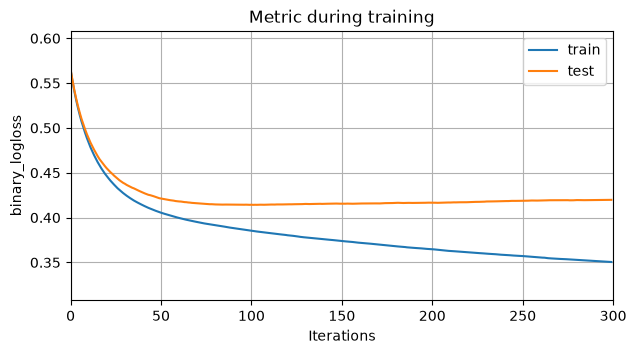

In [6]:
lgb.plot_metric(evals_result, metric="binary_logloss", figsize=(7, 3.5))
plt.show()

`lgb.plot_importance` shows two kinds of built-in importance: `"split"` counts how often a feature is used in a split, `"gain"` adds up the loss reduction of those splits. **Predict:** will the two rankings agree?

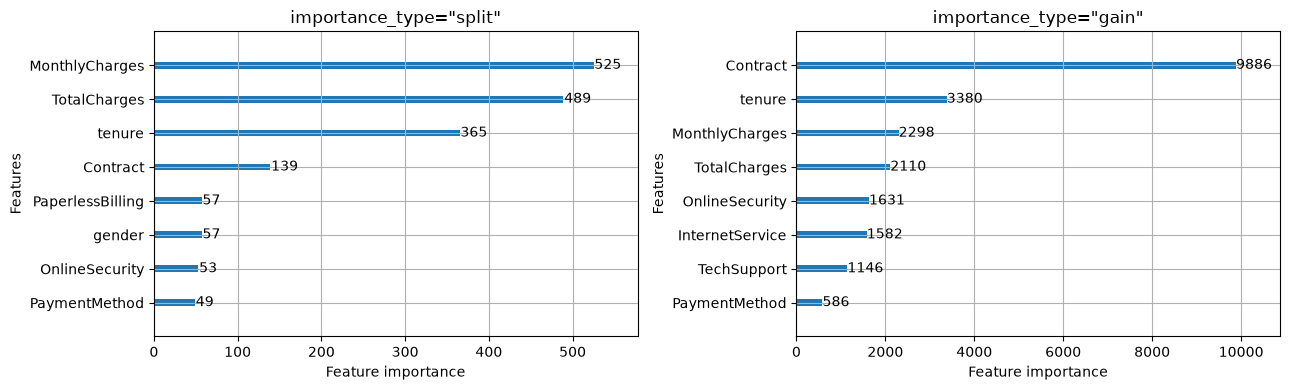

In [7]:
fig, axes = plt.subplots(1, 2, figsize=(13, 4))
for ax, kind in zip(axes, ["split", "gain"]):
    lgb.plot_importance(booster, importance_type=kind, max_num_features=8, ax=ax, precision=0,
                        title=f'importance_type="{kind}"')
plt.tight_layout()
plt.show()

The rankings differ. By split count, the two charges columns lead (525 and 489 splits) and even `gender` is used 57 times; by gain, `Contract` leads by far with only 139 splits. Continuous features offer many thresholds and are split on often, but each split gains little. Section 3 explains why neither is the full story. `lgb.plot_split_value_histogram` shows which thresholds the trees chose for one feature, and `trees_to_dataframe` lists every node of every tree.

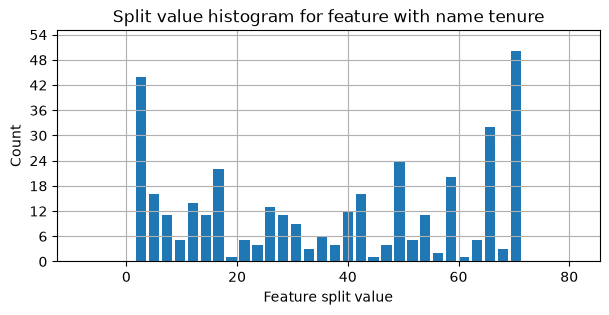

,node_depth,split_feature,threshold,split_gain,value,count
0,1,Contract,0,869.447998,-1.017940,5282
1,2,InternetService,1,277.471008,-0.976774,2930
2,3,tenure,15.5,159.470001,-0.944807,1591
3,4,tenure,1.5,37.070099,-0.907696,768
4,5,NaN,None,NaN,-0.863845,187
5,5,NaN,None,NaN,-0.921810,581
6,4,tenure,51.5,35.415401,-0.979438,823
7,5,NaN,None,NaN,-0.967854,662


In [8]:
lgb.plot_split_value_histogram(booster, feature="tenure", bins=30, figsize=(7, 3))
plt.show()
booster.trees_to_dataframe().query("tree_index == 0")[["node_depth", "split_feature", "threshold",
                                                        "split_gain", "value", "count"]].head(8)

### 1b · CatBoost's own tools (depth: self-study or if time allows)

*Adapted from the [CatBoost tutorial](extras/11-catboost-tutorial.ipynb) (Yandex, Apache-2.0).*

CatBoost's data container is the `Pool`: features, label and the list of categorical columns in one object. Its defaults are often a good baseline. Next we build a training and a test `Pool` from the string columns.

In [9]:
from catboost import Pool, cv

train_pool = Pool(X.loc[Xc_tr.index], y_tr, cat_features=cat)
test_pool = Pool(X.loc[Xc_te.index], y_te, cat_features=cat)

`catboost.cv` runs cross-validation itself and returns the mean and standard deviation of each metric **after every boosting round**, so one call shows the whole learning curve. `train_dir` points CatBoost's log files to our temporary folder.

In [10]:
cv_params = {"loss_function": "Logloss", "custom_metric": ["AUC"], "iterations": 400, "learning_rate": 0.05,
             "depth": 4, "random_seed": 0, "thread_count": 4, "train_dir": TMP, "logging_level": "Silent"}
cv_data = cv(train_pool, cv_params, fold_count=3, stratified=True, seed=0)
best = cv_data["test-AUC-mean"].idxmax()
print(f"best mean CV AUC {cv_data['test-AUC-mean'].max():.3f} +- {cv_data.loc[best, 'test-AUC-std']:.3f} at round {best}")
cv_data[["iterations", "test-Logloss-mean", "test-AUC-mean"]].iloc[[0, 50, 100, 200, 399]].round(4)

best mean CV AUC 0.849 +- 0.011 at round 229


,iterations,test-Logloss-mean,test-AUC-mean
0,0,0.6657,0.7831
50,50,0.4208,0.8450
100,100,0.4138,0.8479
200,200,0.4115,0.8493
399,399,0.4124,0.8490


With an evaluation set, CatBoost can keep only the trees up to the best round (`use_best_model=True`) and stop early when the metric has not improved for `early_stopping_rounds` rounds. Here we split a validation part off the *training* customers (the test customers stay untouched) and compare a model that runs all 1,000 rounds with an early-stopped one. `tree_count_` is the number of trees kept.

In [11]:
X_fit, X_val, y_fit, y_val = train_test_split(X.loc[Xc_tr.index], y_tr, test_size=0.2, stratify=y_tr, random_state=1)
fit_pool, val_pool = Pool(X_fit, y_fit, cat_features=cat), Pool(X_val, y_val, cat_features=cat)
base = dict(iterations=1000, learning_rate=0.1, depth=4, random_seed=0, thread_count=4, verbose=0,
            allow_writing_files=False)
for label, extra in [("all rounds", {"use_best_model": False}), ("early stopping", {"early_stopping_rounds": 40})]:
    t0 = time.time()
    m = CatBoostClassifier(**base, **extra).fit(fit_pool, eval_set=val_pool)
    print(f"{label:<15} trees {m.tree_count_:>4}   test AUC {roc_auc_score(y_te, m.predict_proba(test_pool)[:, 1]):.3f}"
          f"   {time.time() - t0:.1f} s")

all rounds      trees 1000   test AUC 0.832   2.1 s


early stopping  trees  284   test AUC 0.845   0.7 s


`predict_proba(..., ntree_end=k)` uses only the first k trees, without refitting (`staged_predict` yields the same for a series of k); `get_feature_importance` gives CatBoost's built-in importance (by default, how much the prediction changes on average when the feature's value changes). `save_model` and `load_model` store a fitted model; we save it in the temporary folder.

In [12]:
m = CatBoostClassifier(**{**base, "iterations": 300}).fit(fit_pool)
for n_trees in [10, 50, 150, 300]:
    p = m.predict_proba(test_pool, ntree_end=n_trees)          # use only the first n_trees trees
    print(f"after {n_trees} trees: test AUC {roc_auc_score(y_te, p[:, 1]):.3f}")
print(pd.Series(m.get_feature_importance(fit_pool), index=X.columns).nlargest(5).round(1).to_dict())
m.save_model(os.path.join(TMP, "churn.cbm"))
print("reloaded model, same predictions:",
      np.allclose(CatBoostClassifier().load_model(os.path.join(TMP, "churn.cbm")).predict_proba(test_pool),
                  m.predict_proba(test_pool)))

after 10 trees: test AUC 0.834
after 50 trees: test AUC 0.846
after 150 trees: test AUC 0.848
after 300 trees: test AUC 0.845
{'Contract': 21.7, 'MonthlyCharges': 19.5, 'tenure': 16.6, 'TotalCharges': 14.0, 'OnlineSecurity': 3.9}
reloaded model, same predictions: True


> 📖 **Read more:** [extras/10-lightgbm-plotting.ipynb](extras/10-lightgbm-plotting.ipynb) (LightGBM examples) and [extras/11-catboost-tutorial.ipynb](extras/11-catboost-tutorial.ipynb) (CatBoost tutorials): the originals, including custom loss and metric functions in CatBoost and tree drawings with `graphviz`. The XGBoost documentation's [Python tutorials](https://xgboost.readthedocs.io/en/stable/python/index.html) cover the same ground for XGBoost.

## 2 · Categorical features, class weights, early stopping and tuning

### Categorical features

A scikit-learn decision tree needs numbers, so block 1 one-hot encoded the categories: each dummy column allows only splits of the form "category A versus all others". The boosting libraries can split a categorical column **natively** into two *groups* of categories:

- **LightGBM, XGBoost and scikit-learn's `HistGradientBoosting`** sort the categories in a node by their current gradient statistics (roughly, their mean residual) and then search the best cut in that order, as for a number. A split like {Month-to-month} against {One year, Two year} takes one step.
- **CatBoost** replaces each category by an **ordered target statistic**: rows are put in a random order, and each row's category is encoded with the smoothed mean target of the *earlier* rows with that category. A row never sees its own label, the same idea as the cross-fitted target encoding of Session 9.

For a column with three levels the difference is small. For a column with hundreds of levels (product, postcode, store), one-hot encoding creates very wide, sparse tables; native handling or target encoding usually work better.

Next we look at what a `category` column stores: `.cat.categories` is the list of levels, `.cat.codes` the integer code of each row. The libraries work with the codes, so the **same list of levels** must be used for training and new data. `pd.Categorical(values, categories=levels)` enforces a given list.

In [13]:
print(Xc_tr["Contract"].cat.categories.tolist())
new_rows = pd.Series(["Two year", "Month-to-month"])
print("own levels:     ", new_rows.astype("category").cat.codes.tolist())
print("training levels:", pd.Categorical(new_rows, categories=Xc_tr["Contract"].cat.categories).codes.tolist())

['Month-to-month', 'One year', 'Two year']
own levels:      [1, 0]
training levels: [2, 0]


Converted on its own, the new data numbers "Two year" as 1 instead of 2: a model working on raw codes would read it as "One year". Convert once on the whole feature table before splitting (the list of levels is not a leak), or reuse the training levels as above. LightGBM and XGBoost store the training levels and check them at prediction time, but other tools do not.

> 📖 **Read more:** [extras/12-gradient-boosting-categorical.ipynb](extras/12-gradient-boosting-categorical.ipynb) (scikit-learn gallery): five encodings on the Ames housing data; Section 2a below repeats it on the churn data.

### 2a · Five ways to encode categories (depth: self-study or if time allows)

*Adapted from [Categorical feature support in gradient boosting](extras/12-gradient-boosting-categorical.ipynb) (scikit-learn developers, BSD-3-Clause).*

We compare `HistGradientBoostingClassifier` with five treatments of the 15 categorical churn columns:

- **Dropped**: no categorical columns at all (the baseline);
- **One-hot**: `OneHotEncoder`, one 0/1 column per level;
- **Ordinal**: `OrdinalEncoder`, the levels numbered 0, 1, 2, … and treated as ordered numbers;
- **Target**: `TargetEncoder`, each level replaced by the cross-fitted mean churn rate of its rows;
- **Native**: `categorical_features="from_dtype"`, the categories handled by the model itself.

`make_column_selector(dtype_include="category")` picks the categorical columns, so one `make_column_transformer` per encoding is enough. Next we build the five models.

In [14]:
from sklearn.compose import make_column_selector, make_column_transformer
from sklearn.ensemble import HistGradientBoostingClassifier
from sklearn.pipeline import make_pipeline
from sklearn.model_selection import StratifiedKFold
from sklearn.preprocessing import OneHotEncoder, OrdinalEncoder, TargetEncoder

sel = make_column_selector(dtype_include="category")
encoders = {
    "Dropped": ("drop", sel),
    "One-hot": (OneHotEncoder(sparse_output=False, handle_unknown="ignore"), sel),
    "Ordinal": (OrdinalEncoder(handle_unknown="use_encoded_value", unknown_value=np.nan), sel),
    "Target": (TargetEncoder(target_type="binary", cv=StratifiedKFold(5, shuffle=True, random_state=0)), sel),
}
hgb = lambda **kw: HistGradientBoostingClassifier(random_state=0, **kw)
encodings = {name: make_pipeline(make_column_transformer(enc, remainder="passthrough"), hgb())
             for name, enc in encoders.items()}
encodings["Native"] = hgb(categorical_features="from_dtype")

Next we score each model with 5-fold cross-validation on the training customers and plot every fold's ROC AUC against its fit time, with the mean and one standard deviation in black. The best models sit top left: accurate and fast.

Dropped  ROC AUC 0.812   fit 0.05 s


One-hot  ROC AUC 0.834   fit 0.19 s


Ordinal  ROC AUC 0.834   fit 0.10 s


Target   ROC AUC 0.837   fit 0.09 s


Native   ROC AUC 0.834   fit 0.11 s


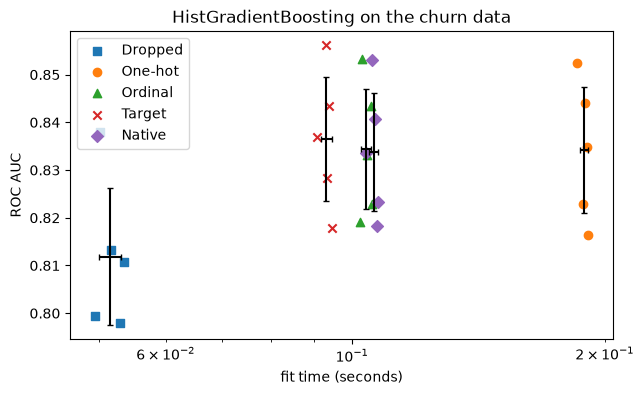

In [15]:
from sklearn.model_selection import cross_validate


def compare_encodings(models, title):
    fig, ax = plt.subplots(figsize=(7, 4))
    for marker, (name, model) in zip("so^xD", models.items()):
        res = cross_validate(model, Xc_tr, y_tr, cv=5, scoring="roc_auc")
        ax.scatter(res["fit_time"], res["test_score"], marker=marker, label=name)
        ax.errorbar(res["fit_time"].mean(), res["test_score"].mean(), xerr=res["fit_time"].std(),
                    yerr=res["test_score"].std(), color="k", capsize=2)
        print(f"{name:<8} ROC AUC {res['test_score'].mean():.3f}   fit {res['fit_time'].mean():.2f} s")
    ax.set_xscale("log")
    ax.set_xlabel("fit time (seconds)")
    ax.set_ylabel("ROC AUC")
    ax.set_title(title)
    ax.legend()
    plt.show()


compare_encodings(encodings, "HistGradientBoosting on the churn data")

Dropping the categories costs most (ROC AUC 0.812 against 0.834 to 0.837). The four encodings that use them are within 0.003 of each other, and one-hot encoding is the slowest to fit, because it creates the most columns to search. With at most four levels per column, the encoding hardly matters on the churn data; the scikit-learn example finds the same on the Ames housing data.

Native handling helps most when the model may make only few splits. If the best split for levels A to F is {A, C, F} against {B, D, E}, one-hot encoding needs three splits and an ordinal encoding four, but native handling needs one. Next we repeat the comparison with deliberately weak models: 15 trees of depth 3. `set_params` with the step name `histgradientboostingclassifier__` reaches into a pipeline.

Dropped  ROC AUC 0.821   fit 0.01 s


One-hot  ROC AUC 0.846   fit 0.04 s
Ordinal  ROC AUC 0.841   fit 0.02 s


Target   ROC AUC 0.845   fit 0.03 s
Native   ROC AUC 0.846   fit 0.02 s


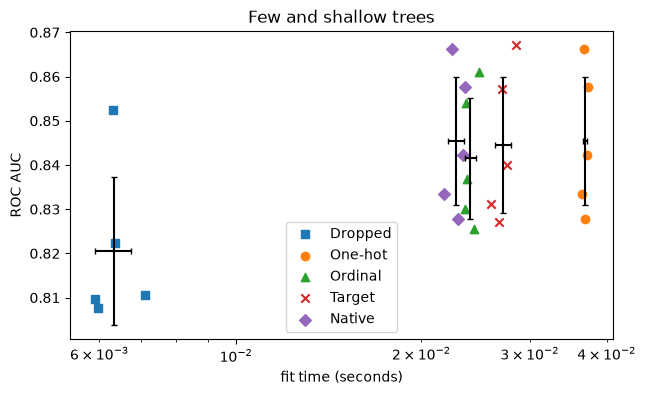

In [16]:
for name, model in encodings.items():
    if name == "Native":
        model.set_params(max_depth=3, max_iter=15)
    else:
        model.set_params(histgradientboostingclassifier__max_depth=3, histgradientboostingclassifier__max_iter=15)
compare_encodings(encodings, "Few and shallow trees")

With only 15 shallow trees, native handling and one-hot encoding (both 0.846) are ahead of the ordinal encoding (0.841), and dropping the categories is clearly worst (0.821). The weak models score higher than the defaults of the first comparison on this small data set, a reminder that default settings are not tuned settings. How much the encoding matters depends on the data and on how many splits the trees may make.

### Class weights

As in Session 8, a **class weight** multiplies the loss of every row of a class, so mistakes on churners count more. The libraries use different names:

| Library | Parameter | Typical value |
|---|---|---|
| scikit-learn, LightGBM | `class_weight="balanced"` | n / (number of classes × rows of the class) |
| XGBoost (binary) | `scale_pos_weight` | number of negatives / number of positives |
| CatBoost | `auto_class_weights="Balanced"` | as scikit-learn |

Weights push the predicted probabilities of the minority class up. At the default threshold of 0.5 the model then predicts churn more often: recall rises, precision falls. The **ranking** of customers hardly changes, so ROC AUC stays almost the same. Weights are one way of moving the decision rule, like lowering the threshold in Session 8.

**Predict before running.** Next we fit XGBoost without weights and with `scale_pos_weight` = stayers / churners in the training data. Which of precision, recall and ROC AUC will move?

In [17]:
from sklearn.metrics import precision_score, recall_score

ratio = (y_tr == 0).sum() / (y_tr == 1).sum()
print("scale_pos_weight =", round(ratio, 2))
for w in [1, ratio]:
    m = XGBClassifier(n_estimators=200, learning_rate=0.05, max_depth=3, enable_categorical=True,
                      scale_pos_weight=w, n_jobs=1).fit(Xc_tr, y_tr)
    p = m.predict(Xc_te)
    print(f"weight {w:.2f}: precision {precision_score(y_te, p):.3f}  recall {recall_score(y_te, p):.3f}  "
          f"ROC AUC {roc_auc_score(y_te, m.predict_proba(Xc_te)[:, 1]):.3f}")

scale_pos_weight = 2.77
weight 1.00: precision 0.670  recall 0.518  ROC AUC 0.845
weight 2.77: precision 0.518  recall 0.790  ROC AUC 0.845


With weights, the model finds 79 % of the churners instead of 52 %, but only 52 % of its alarms are right instead of 67 %. ROC AUC is the same (0.845): the weights changed the operating point, not the ranking.

### 2b · Weights or a lower threshold? (depth: self-study or if time allows)

If weights mostly move the operating point, an unweighted model with a lower threshold should do the same job. Next we lower the threshold of the unweighted XGBoost model until its recall matches the weighted model's, and compare the precision. We also compare the mean predicted probability with the actual churn rate of the test customers: a weighted model's probabilities are no longer calibrated.

In [18]:
weighted = m                                     # the weighted model of the cell above
plain = XGBClassifier(n_estimators=200, learning_rate=0.05, max_depth=3, enable_categorical=True, n_jobs=1).fit(Xc_tr, y_tr)
p_plain, p_weighted = plain.predict_proba(Xc_te)[:, 1], weighted.predict_proba(Xc_te)[:, 1]
target_recall = recall_score(y_te, p_weighted >= 0.5)
for thr in np.arange(0.50, 0.05, -0.01):
    if recall_score(y_te, p_plain >= thr) >= target_recall:
        break
print(f"unweighted, threshold {thr:.2f}: recall {recall_score(y_te, p_plain >= thr):.3f}, "
      f"precision {precision_score(y_te, p_plain >= thr):.3f}")
print(f"mean predicted churn: unweighted {p_plain.mean():.3f}, weighted {p_weighted.mean():.3f}, "
      f"actual {y_te.mean():.3f}")

unweighted, threshold 0.26: recall 0.792, precision 0.506
mean predicted churn: unweighted 0.264, weighted 0.401, actual 0.265


Lowering the threshold of the unweighted model to 0.26 gives about the same recall (0.792) at about the same precision (0.506 against 0.518): weights and a lower threshold reach the same trade-off. But the weighted model predicts an average churn probability of 0.401 when the actual rate is 0.265, while the unweighted model's average (0.264) matches.

> **Note.** If the business needs churn *probabilities* (for an expected-loss calculation), fit without weights and choose the threshold from the costs, or recalibrate the weighted model.

### Early stopping

The number of trees is the most important boosting hyperparameter: too few underfit, too many fit noise. **Early stopping** chooses it during training. A **validation set** is split off the *training* data. After each round the library computes the loss on it; when the loss has not improved for `early_stopping_rounds` rounds, training stops and the model keeps the trees up to the best round (`best_iteration`). It is like baking with the oven light on: you take the cake out when it stops improving, not after a fixed time.

Next we split 20 % of the training customers off as a validation set and train XGBoost with a high learning rate (0.3), so the curve turns quickly. `eval_set` names the validation data; `evals_result()` returns the loss after every round.

In [19]:
Xf_tr, Xf_va, yf_tr, yf_va = train_test_split(Xc_tr, y_tr, test_size=0.2, stratify=y_tr, random_state=1)
xgb = XGBClassifier(n_estimators=500, learning_rate=0.3, max_depth=4, enable_categorical=True, n_jobs=1,
                    eval_metric="logloss", early_stopping_rounds=20)
xgb.fit(Xf_tr, yf_tr, eval_set=[(Xf_tr, yf_tr), (Xf_va, yf_va)], verbose=False)
curves = xgb.evals_result()
print("best round", xgb.best_iteration, "| rounds run", len(curves["validation_1"]["logloss"]),
      "| test ROC AUC", round(roc_auc_score(y_te, xgb.predict_proba(Xc_te)[:, 1]), 3))

best round 25 | rounds run 46 | test ROC AUC 0.841


The plot shows the training loss falling all the time, and the validation loss reaching its minimum and rising again.

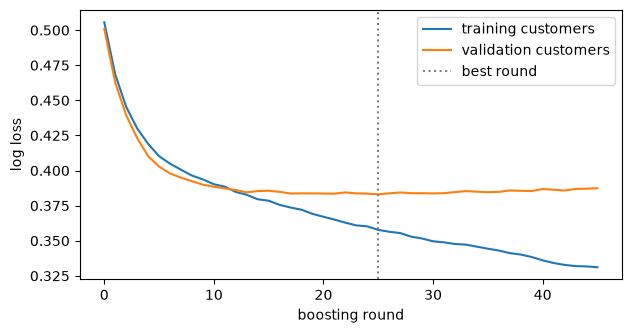

In [20]:
plt.figure(figsize=(7, 3.5))
plt.plot(curves["validation_0"]["logloss"], label="training customers")
plt.plot(curves["validation_1"]["logloss"], label="validation customers")
plt.axvline(xgb.best_iteration, color="grey", ls=":", label="best round")
plt.xlabel("boosting round")
plt.ylabel("log loss")
plt.legend()
plt.show()

> **Note.** Never use the test set as `eval_set`: the number of trees would then be chosen on the test data, and the test score would no longer be an independent estimate. For time-ordered data (Session 12) the validation rows must be *later* than the training rows; for the Berlin listings they must belong to *other hosts* (Session 7). In LightGBM, pass `eval_X`, `eval_y` and the callback `lightgbm.early_stopping(n)`; in CatBoost, `eval_set` and `early_stopping_rounds` (Section 1b); in `HistGradientBoosting`, `early_stopping=True` with an internal `validation_fraction`.

### 2c · Early stopping with and without, in scikit-learn (depth: self-study or if time allows)

*Adapted from [Early stopping in gradient boosting](extras/13-gradient-boosting-early-stopping.ipynb) (scikit-learn developers, BSD-3-Clause).*

scikit-learn's `GradientBoostingClassifier` sets a validation part aside itself: `validation_fraction=0.1` keeps 10 % of the training rows back, and `n_iter_no_change=10` stops when the validation loss has not improved for 10 rounds. `n_estimators_` is the number of trees actually fitted. Next we train one model with up to 500 trees without early stopping and one with it, and time both.

In [21]:
from sklearn.ensemble import GradientBoostingClassifier

X_oh_tr = pd.get_dummies(Xc_tr, dtype=int)
X_oh_te = pd.get_dummies(Xc_te, dtype=int)
params_gb = dict(n_estimators=500, max_depth=3, learning_rate=0.1, random_state=0)
gb_runs = {}
for label, extra in [("full", {}), ("early stopping", {"validation_fraction": 0.1, "n_iter_no_change": 10})]:
    t0 = time.time()
    gb_runs[label] = GradientBoostingClassifier(**params_gb, **extra).fit(X_oh_tr, y_tr)
    print(f"{label:<15} trees {gb_runs[label].n_estimators_:>3}   {time.time() - t0:.1f} s")

full            trees 500   2.5 s


early stopping  trees  64   0.3 s


`staged_predict_proba` yields the predictions after 1, 2, 3, … trees. Next we compute the log loss on the training and the test customers after every tree, for both models.

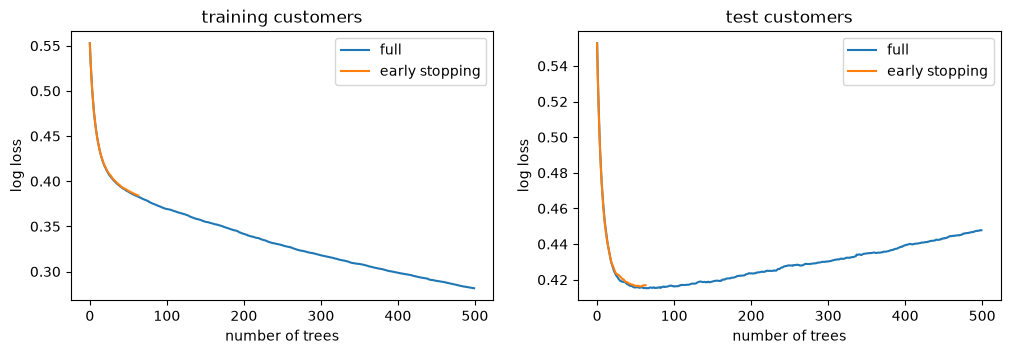

In [22]:
from sklearn.metrics import log_loss

fig, axes = plt.subplots(1, 2, figsize=(12, 3.5))
for label, model in gb_runs.items():
    for ax, (Xs, ys) in zip(axes, [(X_oh_tr, y_tr), (X_oh_te, y_te)]):
        ax.plot([log_loss(ys, p[:, 1]) for p in model.staged_predict_proba(Xs)], label=label)
axes[0].set_title("training customers")
axes[1].set_title("test customers")
for ax in axes:
    ax.set_xlabel("number of trees")
    ax.set_ylabel("log loss")
    ax.legend()
plt.show()

Early stopping keeps 64 of the 500 trees and fits in about a tenth of the time. On the training customers the full model's loss keeps falling. On the test customers it reaches its minimum at roughly 70 to 100 trees and then rises steadily: the remaining trees fit noise. The early-stopped model stops close to that minimum. (Its curve differs slightly from the full model's because 10 % of the training rows were held back.)

### Tuning

The parameters that matter most, roughly in this order:

1. **Number of trees and learning rate**, together: a small learning rate (0.01 to 0.1) needs more trees. Fix the learning rate and set the number of trees by early stopping, or search both.
2. **Tree size**: `max_depth` (XGBoost, CatBoost `depth`) or `num_leaves` (LightGBM), and the minimum data per leaf (`min_child_samples`, `min_child_weight`).
3. **Subsampling**: `subsample` (rows per tree) and `colsample_bytree` (features per tree), typically 0.5 to 1.0.
4. **Regularisation**: `reg_lambda`, `reg_alpha`.

With several parameters, a **randomised search** (`RandomizedSearchCV`, Session 7) is more efficient than a grid. It draws combinations from distributions: `loguniform(0.01, 0.3)` draws a learning rate on a log scale, `randint(4, 64)` an integer, `uniform(0.5, 0.5)` a number between 0.5 and 1.0. The best cross-validated score of a search is optimistic, because it is the maximum over many tries, so we report a held-out score next to it.

Next we search 15 LightGBM settings with 5-fold cross-validation on the training customers. `subsample_freq=1` switches row subsampling on.

In [23]:
from scipy.stats import loguniform, randint, uniform
from sklearn.model_selection import RandomizedSearchCV, StratifiedKFold

t0 = time.time()
search = RandomizedSearchCV(
    LGBMClassifier(n_estimators=200, subsample_freq=1, n_jobs=1, verbose=-1, random_state=0),
    {"learning_rate": loguniform(0.01, 0.3), "num_leaves": randint(4, 64),
     "min_child_samples": randint(5, 100), "subsample": uniform(0.5, 0.5)},
    n_iter=15, scoring="roc_auc", cv=StratifiedKFold(5, shuffle=True, random_state=0), random_state=0,
).fit(Xc_tr, y_tr)
print({k: round(float(v), 3) for k, v in search.best_params_.items()})
print(f"best CV ROC AUC {search.best_score_:.3f} | test ROC AUC "
      f"{roc_auc_score(y_te, search.predict_proba(Xc_te)[:, 1]):.3f} | {time.time() - t0:.0f} s")

{'learning_rate': 0.034, 'min_child_samples': 6.0, 'num_leaves': 5.0, 'subsample': 0.55}
best CV ROC AUC 0.850 | test ROC AUC 0.847 | 6 s


The search prefers very small trees (5 leaves) and a low learning rate, which fits the observation that the churn effects are simple. The held-out score (0.847) is close to the cross-validated one (0.850); the gain over the untuned LightGBM of Section 1 (0.842) is small. Knowing when tuning is not worth it is also a result.

> **Note.** Early stopping inside `RandomizedSearchCV` is awkward: the early-stopping set would have to be split off each training fold. Either fix the number of trees in the search (as above), or fix the learning rate, search the rest, and use early stopping only for the final fit.

> **Note.** *Many classes, few rows per class.* A multiclass booster fits one tree per class and round. For a rare class the second derivative of the loss in a leaf can be close to zero, and the leaf value (gradient divided by that derivative) explodes. Raise the minimum hessian per leaf (`min_sum_hessian_in_leaf` in LightGBM, default 0.001) or add L2 regularisation (`l2_regularization` in `HistGradientBoostingClassifier`, default 0). If a multiclass booster is worse than a constant prediction, suspect this first. Sessions 13 to 16 have many classes.

### 2d · Which hyperparameters matter, for forests and for boosting (depth: self-study or if time allows)

*Adapted from [Hyperparameter tuning](extras/14-ensemble-hyperparameters.ipynb) (INRIA scikit-learn MOOC, CC BY 4.0).*

**Random forests.** The number of trees needs no tuning: it only has to be large enough that doubling it does not improve the validation score. What is worth tuning:

- `max_features`: the size of the random feature subset per split (block 1, Section 3b);
- `max_depth` or `max_leaf_nodes`: `max_depth` grows symmetric trees, `max_leaf_nodes` does not;
- `min_samples_leaf`: a split is only made if each side keeps at least this many rows. Small values let single rows be isolated; large values prevent deep trees.

Trees in a forest are *meant* to be deep and to overfit individually; averaging removes the overfitting. Next we run a randomised search over these three for a forest on the churn data (one-hot features, 3-fold CV) and print the five best settings.

In [24]:
from sklearn.ensemble import RandomForestClassifier

rf_search = RandomizedSearchCV(
    RandomForestClassifier(n_estimators=100, n_jobs=4, random_state=0),
    {"max_features": [1, 2, 5, 10, None], "max_leaf_nodes": [10, 100, 1000, None],
     "min_samples_leaf": [1, 2, 5, 10, 20, 50, 100]},
    n_iter=10, scoring="roc_auc", cv=3, random_state=0).fit(X_oh_tr, y_tr)
cols = ["param_max_features", "param_max_leaf_nodes", "param_min_samples_leaf", "mean_test_score", "std_test_score"]
pd.DataFrame(rf_search.cv_results_)[cols].sort_values("mean_test_score", ascending=False).head(5).round(3)

,param_max_features,param_max_leaf_nodes,param_min_samples_leaf,mean_test_score,std_test_score
6,None,1000,50,0.846,0.005
7,None,None,20,0.845,0.003
4,10,100,2,0.844,0.003
0,2,1000,10,0.843,0.005
8,None,100,10,0.842,0.003


The two best forests consider all features at each split and use large leaves (`min_samples_leaf` of 50 and 20), but the top five settings are within 0.004 ROC AUC of each other, about one standard deviation across folds. Ten random settings are enough to see which region works, not to rank settings precisely.

**Gradient boosting.** Here the parameters are coupled and cannot be set one after another. The trees must be shallow (typically 3 to 8 levels, or 8 to 256 leaves): a fully grown first tree would fit the training data perfectly and leave no residuals for the next ones. Deeper trees correct the residuals faster and need fewer rounds; shallow trees need more. The learning rate scales each correction: a small rate needs more trees, a large rate trains faster but risks overfitting. Next we search `max_iter`, `max_leaf_nodes` and `learning_rate` for `HistGradientBoostingClassifier` together.

In [25]:
hgb_search = RandomizedSearchCV(
    HistGradientBoostingClassifier(categorical_features="from_dtype", random_state=0),
    {"max_iter": [3, 10, 30, 100, 300], "max_leaf_nodes": [2, 5, 10, 20, 50],
     "learning_rate": loguniform(0.01, 1)},
    n_iter=15, scoring="roc_auc", cv=3, random_state=0).fit(Xc_tr, y_tr)
cols = ["param_max_iter", "param_max_leaf_nodes", "param_learning_rate", "mean_test_score", "std_test_score"]
pd.DataFrame(hgb_search.cv_results_)[cols].sort_values("mean_test_score", ascending=False).head(6).round(3)

,param_max_iter,param_max_leaf_nodes,param_learning_rate,mean_test_score,std_test_score
2,300,2,0.196,0.850,0.004
9,100,2,0.110,0.848,0.006
8,10,20,0.089,0.844,0.004
6,3,20,0.198,0.840,0.005
5,3,5,0.710,0.839,0.009
0,3,20,0.125,0.838,0.005


The best settings combine many trees with tiny trees (2 leaves, that is stumps) and a moderate learning rate; settings with only 3 or 10 trees need larger trees and higher learning rates and still score lower. The best value of each parameter depends on the others. (The INRIA notebook adds that it is better to fix `max_iter` large and use early stopping than to tune it.)

| Bagging and random forests | Boosting |
|---|---|
| fit trees **independently** | fit trees **one after another** |
| each **deep tree overfits** | each **shallow tree underfits** |
| averaging **reduces overfitting** | adding trees **reduces underfitting** |
| more trees never hurt | too many trees overfit |
| no learning rate | the learning rate scales each correction |

> 📖 **Read more:** [extras/13-gradient-boosting-early-stopping.ipynb](extras/13-gradient-boosting-early-stopping.ipynb) (scikit-learn gallery) and [extras/14-ensemble-hyperparameters.ipynb](extras/14-ensemble-hyperparameters.ipynb) (INRIA MOOC): the originals, on the California housing data.

## 3 · Interpretation: feature importance, permutation importance and SHAP

A boosted model with hundreds of trees cannot be read like the depth-2 tree of block 1. We still need to know what it has learned: to check that it uses sensible information, to find leaks and bugs, and to explain it to the people who rely on it.

**Built-in (impurity-based) importance.** `feature_importances_` in scikit-learn, "gain" in the boosting libraries: for each feature, the total loss reduction of all splits that use it. It comes for free, but it has two known biases. It favours features with many distinct values (they offer many thresholds), and it is computed on the *training* data, so it also counts splits that only fit noise.

**Permutation importance** (Breiman, 2001) asks: how much worse does the model get if this feature's values are shuffled? Shuffling a column breaks its link with the target but keeps its distribution. The steps:

1. Compute the model's score on a data set, preferably held-out data.
2. Shuffle one column, recompute the score; the importance is the drop. Repeat several times and average.

Worked example: a model has a test ROC AUC of 0.84. Shuffling `Contract` lowers it to 0.75, so the importance of `Contract` is 0.09. Shuffling `gender` leaves it at 0.84: importance 0, the model does not rely on gender.

Next we fit one LightGBM model, read its gain importance (`importance_type="gain"`), and compute `permutation_importance` on the test customers with 10 repeats.

In [26]:
from sklearn.inspection import permutation_importance

lgbm = LGBMClassifier(n_estimators=300, learning_rate=0.05, num_leaves=8, n_jobs=1, verbose=-1,
                      random_state=0, importance_type="gain").fit(Xc_tr, y_tr)
print("test ROC AUC", round(roc_auc_score(y_te, lgbm.predict_proba(Xc_te)[:, 1]), 3))
perm = permutation_importance(lgbm, Xc_te, y_te, scoring="roc_auc", n_repeats=10, random_state=0)
imp = pd.DataFrame({"gain share": lgbm.feature_importances_ / lgbm.feature_importances_.sum(),
                    "permutation (test)": perm.importances_mean}, index=X.columns)
imp.sort_values("permutation (test)", ascending=False).head(8).round(3)

test ROC AUC 0.842


,gain share,permutation (test)
Contract,0.400,0.088
tenure,0.137,0.056
InternetService,0.064,0.013
MonthlyCharges,0.093,0.011
OnlineSecurity,0.066,0.006
TotalCharges,0.085,0.005
TechSupport,0.046,0.004
PaymentMethod,0.024,0.004


Both measures put `Contract` and `tenure` first, but they disagree further down: by gain share the monthly and total charges come before the internet service type, by permutation the order is reversed. The charges are continuous and offer many split points; on new customers they add less than their gain suggests.

> **Note.** *Correlated features share importance.* `tenure` and `TotalCharges` (about tenure × monthly charges) carry similar information. Shuffling one hurts little, because the model can fall back on the other, so both can look unimportant although together they matter. Check correlations, or shuffle correlated groups together.

> **Note.** Importance describes the *model*, not the world. "Fibre-optic internet is important for the churn prediction" does not mean fibre optic *causes* churn; it may stand for price, region or customer type.

**SHAP values** (SHapley Additive exPlanations; Lundberg & Lee, 2017) split *one* prediction into additive contributions of the features:

model output for customer i = base value + φ₁ + φ₂ + … + φ_p.

The **base value** is the average model output on the background data; φ_j is the contribution of feature j for this customer. For boosted classifiers the output is in **log-odds**, so the contributions add up on the log-odds scale. The φ_j are Shapley values from game theory: the average change in the prediction when feature j joins, over all orders in which the features could join. `shap.TreeExplainer` computes them exactly and fast for tree ensembles (Lundberg et al., 2020). The mean absolute SHAP value of a feature is a **global** importance; the single values are **local** explanations.

Next we explain the test customers. `explainer(X)` returns an `Explanation` object with `.values` (one row per customer, one column per feature), `.base_values` and `.data`.

In [27]:
import shap

explainer = shap.TreeExplainer(lgbm)
sv = explainer(Xc_te)
print(sv.values.shape, "base value", round(float(sv.base_values[0]), 3))
pd.Series(np.abs(sv.values).mean(axis=0), index=X.columns).nlargest(6).round(3)

(1761, 19) base value -1.718


Contract           0.821
tenure             0.487
OnlineSecurity     0.257
MonthlyCharges     0.250
InternetService    0.219
TechSupport        0.208
dtype: float64

The **beeswarm plot** shows one dot per customer and feature: the position is the SHAP value, the colour the feature's value (red high, blue low). Categorical columns appear grey because they have no "high" or "low".

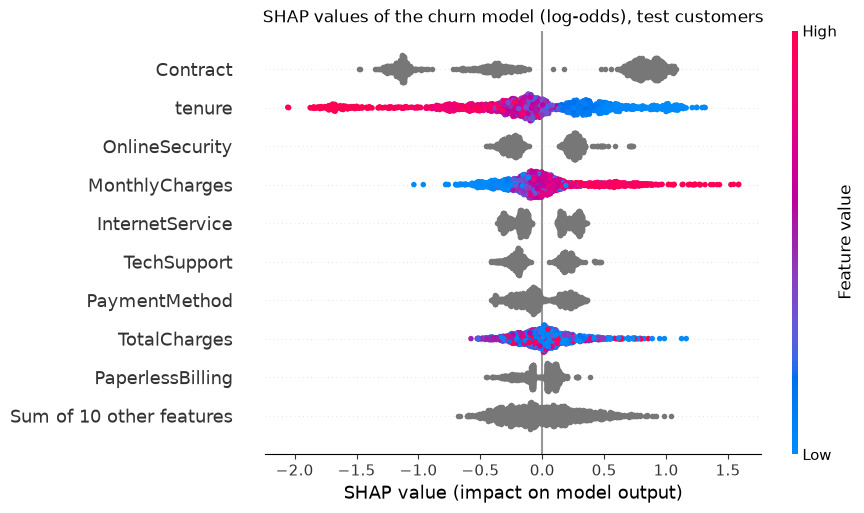

In [28]:
shap.plots.beeswarm(sv, max_display=10, show=False)
plt.title("SHAP values of the churn model (log-odds), test customers")
plt.show()

Next we check the additivity for the first test customer: the base value plus the sum of the contributions must equal the model's log-odds, `log(p / (1 − p))`. The **waterfall plot** shows how the contributions move the prediction from the base value to the final output.

base + contributions: -0.447 | model log-odds: -0.447 | probability: 0.39


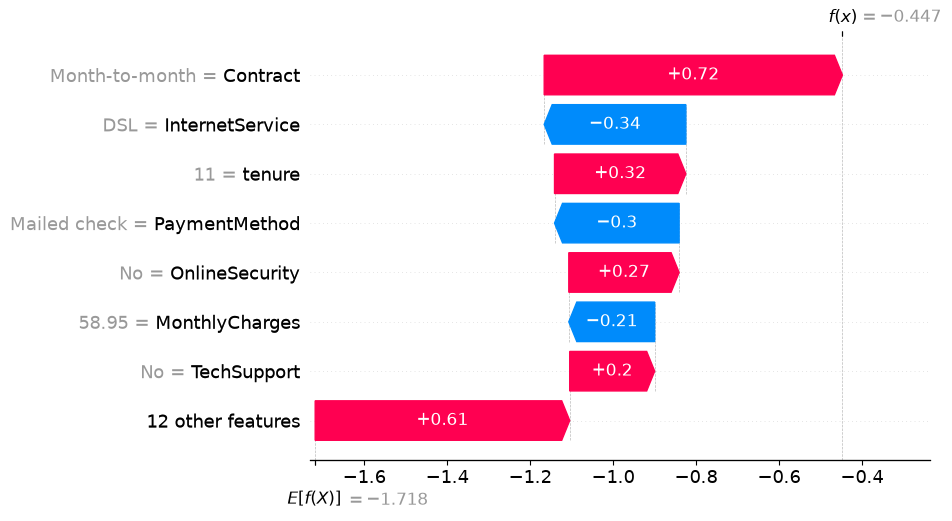

In [29]:
i = 0
p = lgbm.predict_proba(Xc_te.iloc[[i]])[0, 1]
print("base + contributions:", round(float(sv.base_values[i] + sv.values[i].sum()), 3),
      "| model log-odds:", round(float(np.log(p / (1 - p))), 3), "| probability:", round(p, 3))
shap.plots.waterfall(sv[i], max_display=8)

The base value is −1.718 on the log-odds scale, a churn probability of 15 %, lower than the churn rate of 26.5 %, because the average of log-odds is not the log-odds of the average. For this customer, the contributions move the prediction to −0.447 log-odds, a churn probability of 39 %, exactly the model's output. Across all customers, `Contract` and `tenure` have the largest mean absolute SHAP values, in line with the permutation importance.

Use SHAP first as a tool for the modeller:

- **Find leaks.** A feature that should be weak but dominates the SHAP summary is the most common sign of target leakage (Session 9). The worked example shows this on the Berlin data.
- **Find bugs.** An unexpected direction (a higher price *lowers* churn risk) or an effect of an ID column points to an error in the feature pipeline.
- **Check single cases.** For a surprising prediction, the SHAP values show which inputs drove it, often revealing a data problem in that row.
- **Find proxies.** A large contribution of a postcode or a name-derived feature may signal discrimination.

> **Note.** The `shap` package changes its interface often. Pin the version, check shapes (multiclass models add a class dimension), and note whether values are on the log-odds or the probability scale.

### 3a · Impurity importance is biased: two random columns (depth: self-study or if time allows)

*Adapted from [Permutation importance vs random forest feature importance (MDI)](extras/15-permutation-importance.ipynb) (scikit-learn developers, BSD-3-Clause).*

To expose the two biases, we add two columns that have nothing to do with churn: `random_num`, a continuous random number (as many distinct values as customers), and `random_cat`, a random category with three levels. Next we fit a random forest of fully grown trees (one-hot features) and check its accuracy first: there is no point in interpreting a model that predicts badly.

In [30]:
rng = np.random.default_rng(42)
Xr_tr = X_oh_tr.assign(random_cat=rng.integers(3, size=len(X_oh_tr)), random_num=rng.normal(size=len(X_oh_tr)))
Xr_te = X_oh_te.assign(random_cat=rng.integers(3, size=len(X_oh_te)), random_num=rng.normal(size=len(X_oh_te)))
rf = RandomForestClassifier(n_estimators=100, random_state=0, n_jobs=4).fit(Xr_tr, y_tr)
print(f"train accuracy {rf.score(Xr_tr, y_tr):.3f} | test accuracy {rf.score(Xr_te, y_te):.3f}")

train accuracy 1.000 | test accuracy 0.788


The forest memorises the training customers almost completely, yet still generalises reasonably thanks to bagging. Next we plot its impurity importance (**MDI**, mean decrease in impurity) for the ten highest-ranked columns.

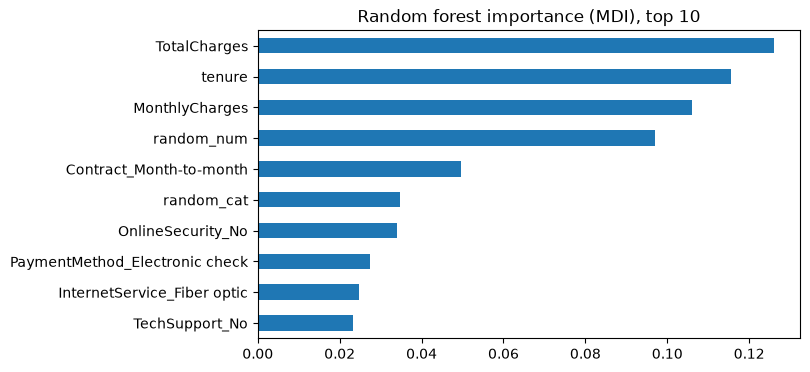

rank of random_num: 4 | rank of random_cat: 6 of 47


In [31]:
mdi = pd.Series(rf.feature_importances_, index=Xr_tr.columns).sort_values()
ax = mdi.tail(10).plot.barh(figsize=(7, 4))
ax.set_title("Random forest importance (MDI), top 10")
plt.show()
print("rank of random_num:", int((mdi > mdi["random_num"]).sum()) + 1, "| rank of random_cat:",
      int((mdi > mdi["random_cat"]).sum()) + 1, "of", len(mdi))

By impurity, `random_num` ranks 4th of 47 columns and `random_cat` 6th, ahead of real features such as the internet service type. The continuous random column offers thousands of thresholds, and fully grown trees use it to separate single training customers.

Next we compute permutation importance on the test customers and on the training customers and draw both as box plots of the 10 repeats. A helper keeps the plotting code in one place.

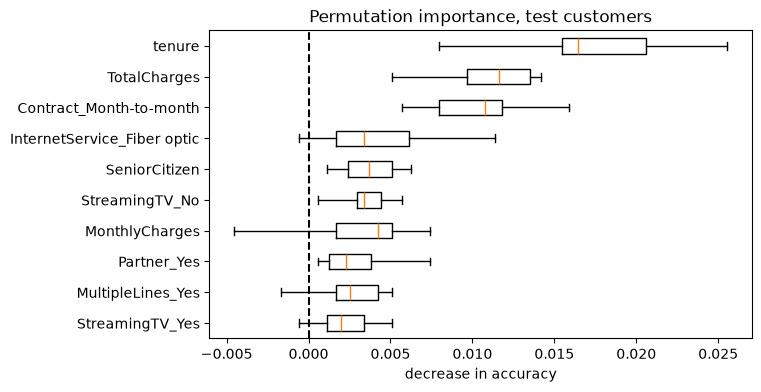

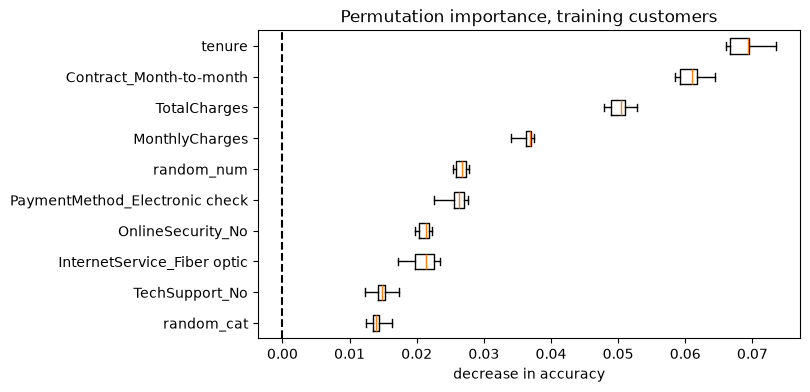

random columns, test:  {'random_num': -0.001, 'random_cat': -0.003}
random columns, train: {'random_num': 0.027, 'random_cat': 0.014}


In [32]:
def plot_perm(model, Xs, ys, title, top=10):
    res = permutation_importance(model, Xs, ys, n_repeats=10, random_state=42, n_jobs=1)
    order = res.importances_mean.argsort()[-top:]
    fig, ax = plt.subplots(figsize=(7, 4))
    ax.boxplot(res.importances[order].T, orientation="horizontal", tick_labels=Xs.columns[order], whis=10)
    ax.axvline(0, color="k", ls="--")
    ax.set_xlabel("decrease in accuracy")
    ax.set_title(title)
    plt.show()
    return pd.Series(res.importances_mean, index=Xs.columns)


perm_test = plot_perm(rf, Xr_te, y_te, "Permutation importance, test customers")
perm_train = plot_perm(rf, Xr_tr, y_tr, "Permutation importance, training customers")
print("random columns, test: ", perm_test[["random_num", "random_cat"]].round(3).to_dict())
print("random columns, train:", perm_train[["random_num", "random_cat"]].round(3).to_dict())

On the test customers, shuffling the random columns changes nothing (−0.001 and −0.003). On the training customers they look useful (0.027 and 0.014): the forest has used them to memorise the training data. Comparing permutation importance on training and test data is therefore a quick overfitting check.

Limiting the trees (`min_samples_leaf=20`) reduces the overfitting. Next we refit and compare the importance of the random columns again.

In [33]:
rf20 = RandomForestClassifier(n_estimators=100, min_samples_leaf=20, random_state=0, n_jobs=4).fit(Xr_tr, y_tr)
print(f"train accuracy {rf20.score(Xr_tr, y_tr):.3f} | test accuracy {rf20.score(Xr_te, y_te):.3f}")
for name, (Xs, ys) in {"train": (Xr_tr, y_tr), "test": (Xr_te, y_te)}.items():
    r = permutation_importance(rf20, Xs, ys, n_repeats=10, random_state=42, n_jobs=1)
    print(name, pd.Series(r.importances_mean, index=Xs.columns)[["random_num", "random_cat"]].round(4).to_dict())

train accuracy 0.824 | test accuracy 0.793


train {'random_num': 0.0028, 'random_cat': 0.0007}


test {'random_num': 0.0015, 'random_cat': -0.0015}


With leaves of at least 20 customers, training and test accuracy are close (0.824 and 0.793), and the random columns are near zero on both sets. The ranking of the real features stays the same.

### 3b · Coefficients versus importances (depth: self-study or if time allows)

*Adapted from [Feature importance](extras/16-feature-importance.ipynb) (INRIA scikit-learn MOOC, CC BY 4.0).*

The current churn model is a logistic regression. Its coefficients look like an importance measure, but two cautions apply. First, a coefficient is a **conditional** association: the change in log-odds when one feature changes *and all others stay fixed*. Second, coefficients are in the units of their feature, so they can only be compared after standardising the features. Next we fit the logistic regression on unscaled and on standardised one-hot features and compare the three numeric coefficients.

In [34]:
from sklearn.linear_model import LogisticRegression
from sklearn.preprocessing import StandardScaler

raw = LogisticRegression(max_iter=5000).fit(X_oh_tr, y_tr)
scaled = make_pipeline(StandardScaler(), LogisticRegression(max_iter=5000)).fit(X_oh_tr, y_tr)
coefs = pd.DataFrame({"unscaled": raw.coef_[0], "standardised": scaled[-1].coef_[0]}, index=X_oh_tr.columns)
print(coefs.loc[num].round(4))
print("standard deviations:", X_oh_tr[num].std().round(1).to_dict())

                unscaled  standardised
SeniorCitizen     0.2403        0.0890
tenure           -0.0559       -1.3095
MonthlyCharges   -0.0163       -0.5722
TotalCharges      0.0003        0.5892
standard deviations: {'SeniorCitizen': 0.4, 'tenure': 24.5, 'MonthlyCharges': 30.1, 'TotalCharges': 2252.1}


Unscaled, `TotalCharges` has a tiny coefficient (0.0003 per euro) only because it is measured in thousands of euros (standard deviation 2,252); standardised, it is one of the largest (0.59). `tenure` and `TotalCharges` have opposite signs although both mean "long-standing customer": they are strongly correlated, and each coefficient is the effect of one *holding the other fixed*.

Coefficients can also be unstable when features are correlated. Next we refit the standardised model on 5 × 5 cross-validation splits (`RepeatedKFold`, `return_estimator=True` keeps every fitted model) and draw the spread of each numeric coefficient.

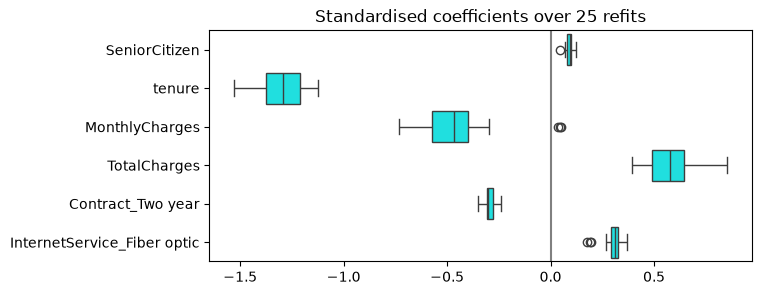

In [35]:
import seaborn as sns
from sklearn.model_selection import RepeatedKFold

cv_model = cross_validate(scaled, X_oh_tr, y_tr, cv=RepeatedKFold(n_splits=5, n_repeats=5, random_state=0),
                          return_estimator=True)
coef_runs = pd.DataFrame([est[-1].coef_[0] for est in cv_model["estimator"]], columns=X_oh_tr.columns)
plt.figure(figsize=(7, 3))
sns.boxplot(data=coef_runs[num + ["Contract_Two year", "InternetService_Fiber optic"]], orient="h", color="cyan")
plt.axvline(0, color=".5")
plt.title("Standardised coefficients over 25 refits")
plt.show()

The coefficients of the correlated trio `tenure`, `MonthlyCharges` and `TotalCharges` vary much more across refits than those of the contract and internet dummies. Correlated features make coefficients unstable; their individual values should not be over-interpreted.

Permutation importance itself is simple enough to write by hand, which makes clear what `permutation_importance` does. Next we shuffle `tenure` in the test data ten times and record the drop in the logistic regression's ROC AUC.

In [36]:
def score_after_permutation(model, Xs, ys, feature, rng):
    X_perm = Xs.copy()
    X_perm[feature] = rng.permutation(X_perm[feature].to_numpy())
    return roc_auc_score(ys, model.predict_proba(X_perm)[:, 1])


base_score = roc_auc_score(y_te, scaled.predict_proba(X_oh_te)[:, 1])
rng = np.random.default_rng(0)
drops = [base_score - score_after_permutation(scaled, X_oh_te, y_te, "tenure", rng) for _ in range(10)]
print(f"permutation importance of tenure: {np.mean(drops):.4f} +- {np.std(drops):.4f}")

permutation importance of tenure: 0.1841 +- 0.0058


### 3c · SHAP dependence and interactions (depth: self-study or if time allows)

*Adapted from [Census income classification with XGBoost](extras/17-shap-census-xgboost.ipynb) (SHAP authors, MIT).*

XGBoost offers several built-in importances: `weight` (how often a feature is split on), `cover` (how many rows those splits affect) and `gain` (their loss reduction). Next we fit an XGBoost model on the numeric and one-hot features and plot all three. **Predict:** will they agree?

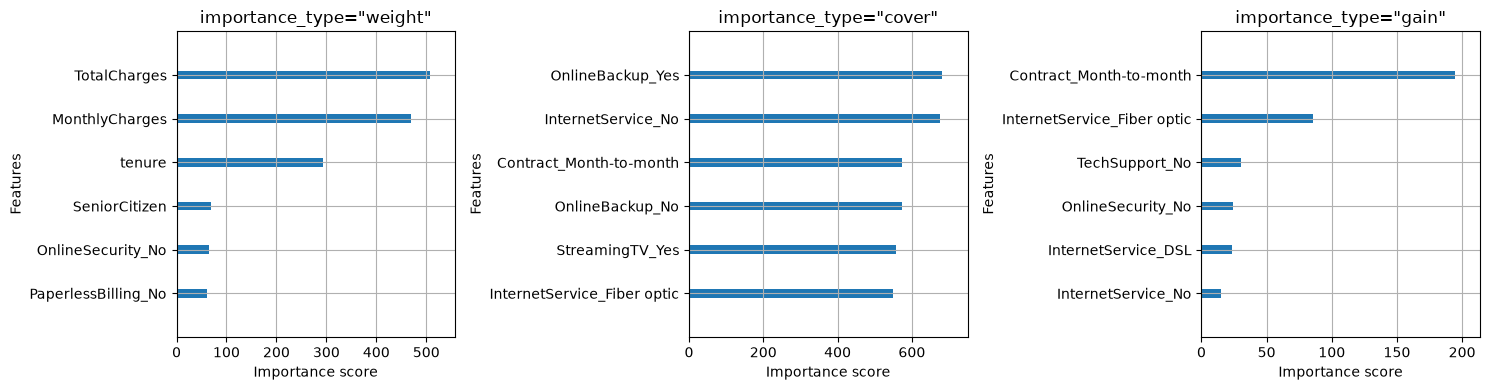

In [37]:
import xgboost

xgb_model = XGBClassifier(n_estimators=300, learning_rate=0.05, max_depth=3, n_jobs=1).fit(X_oh_tr, y_tr)
fig, axes = plt.subplots(1, 3, figsize=(15, 4))
for ax, kind in zip(axes, ["weight", "cover", "gain"]):
    xgboost.plot_importance(xgb_model, importance_type=kind, max_num_features=6, ax=ax, show_values=False,
                            title=f'importance_type="{kind}"')
plt.tight_layout()
plt.show()

The three rankings contradict each other, which is the SHAP authors' argument for SHAP values: they come with consistency guarantees. A **SHAP dependence plot** draws one feature's value against its SHAP value for every customer. Unlike a partial dependence plot, it shows the vertical spread caused by **interactions**: at the same tenure, the contribution differs depending on the other features. `shap.plots.scatter(sv[:, "tenure"], color=sv[:, "MonthlyCharges"])` colours the dots by a second feature.

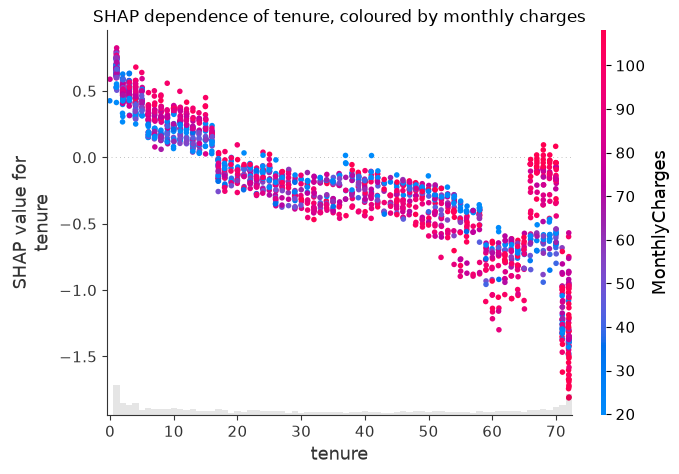

In [38]:
sv_xgb = shap.TreeExplainer(xgb_model)(X_oh_te)
shap.plots.scatter(sv_xgb[:, "tenure"], color=sv_xgb[:, "MonthlyCharges"], show=False)
plt.title("SHAP dependence of tenure, coloured by monthly charges")
plt.show()

A model with trees of depth 1 (stumps) cannot represent interactions: every feature then has the same effect whatever the others are. Next we fit such a model and draw the same plot. **Predict:** what happens to the vertical spread?

test ROC AUC: depth 3 0.842 | depth 1 0.85


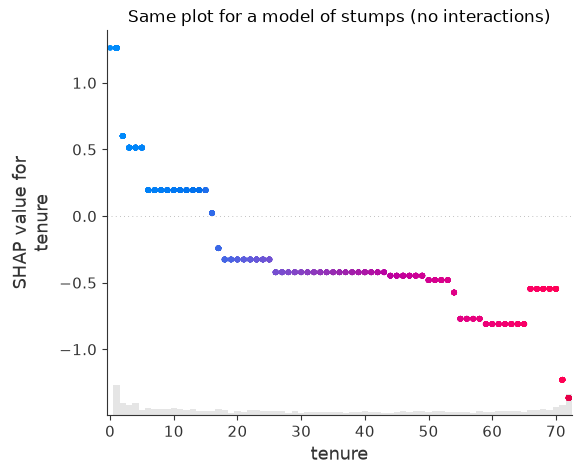

In [39]:
stumps = XGBClassifier(n_estimators=600, learning_rate=0.05, max_depth=1, n_jobs=1).fit(X_oh_tr, y_tr)
sv_stumps = shap.TreeExplainer(stumps)(X_oh_te)
print("test ROC AUC: depth 3", round(roc_auc_score(y_te, xgb_model.predict_proba(X_oh_te)[:, 1]), 3),
      "| depth 1", round(roc_auc_score(y_te, stumps.predict_proba(X_oh_te)[:, 1]), 3))
with np.errstate(invalid="ignore"):                     # no interactions: shap divides by a zero spread
    shap.plots.scatter(sv_stumps[:, "tenure"], color=sv_stumps[:, "MonthlyCharges"], show=False)
plt.title("Same plot for a model of stumps (no interactions)")
plt.show()

With stumps, each tenure value has exactly one SHAP value: no vertical spread, because no feature can change the effect of another. The depth-3 model shows a spread at the same tenure, coloured by monthly charges, which are interactions. On the churn data the stump model even scores slightly higher (0.850 against 0.842), another sign that the churn effects are simple.

### 3d · Why SHAP values are not causal effects (depth: self-study or if time allows)

*Adapted from [Be careful when interpreting predictive models in search of causal insights](extras/18-shap-causal-caution.ipynb) (Dillon, LaRiviere, Lundberg, Roth & Syrgkanis, SHAP authors, MIT).*

A predictive model learns correlations. That is fine for **prediction tasks** ("which customers will renew?"), but not for **causal tasks** ("will a bigger discount make customers renew?"). The SHAP authors show this with a simulated subscription business in which we know the true causes. An unobserved variable, *product need*, drives renewal; customers who need the product report more bugs (they use it more), and the sales team gives bigger discounts to customers it thinks are less interested. Next we copy their data generator. `fixed={...}` lets us *set* a variable for everyone, as in an experiment.

In [40]:
import scipy.special
import scipy.stats


class FixableDataFrame(pd.DataFrame):
    """A DataFrame in which some columns can be fixed to a value (an intervention)."""

    def __init__(self, *args, fixed={}, **kwargs):
        self.__dict__["__fixed_var_dictionary"] = fixed
        super().__init__(*args, **kwargs)

    def __setitem__(self, key, value):
        out = super().__setitem__(key, value)
        if isinstance(key, str) and key in self.__dict__["__fixed_var_dictionary"]:
            out = super().__setitem__(key, self.__dict__["__fixed_var_dictionary"][key])
        return out

The generator writes down every cause. Read the last formula: the renewal depends on product need, usage, economy, discount (positively), bugs *faced* (negatively), sales calls, interactions and time since the last upgrade, but **not** on bugs *reported* and **not** on ad spend.

In [41]:
def generator(n, fixed={}, seed=0):
    """The generative model of the subscriber retention example (SHAP documentation)."""
    if seed is not None:
        np.random.seed(seed)
    X = FixableDataFrame(fixed=fixed)
    X["Sales calls"] = np.random.uniform(0, 4, size=(n,)).round()
    X["Interactions"] = X["Sales calls"] + np.random.poisson(0.2, size=(n,))
    X["Economy"] = np.random.uniform(0, 1, size=(n,))
    X["Last upgrade"] = np.random.uniform(0, 20, size=(n,))
    X["Product need"] = X["Sales calls"] * 0.1 + np.random.normal(0, 1, size=(n,))
    X["Discount"] = ((1 - scipy.special.expit(X["Product need"])) * 0.5 + 0.5 * np.random.uniform(0, 1, size=(n,))) / 2
    X["Monthly usage"] = scipy.special.expit(X["Product need"] * 0.3 + np.random.normal(0, 1, size=(n,)))
    X["Ad spend"] = (X["Monthly usage"] * np.random.uniform(0.99, 0.9, size=(n,))
                     + (X["Last upgrade"] < 1) + (X["Last upgrade"] < 2))
    X["Bugs faced"] = np.array([np.random.poisson(v * 2) for v in X["Monthly usage"]])
    X["Bugs reported"] = (X["Bugs faced"] * scipy.special.expit(X["Product need"])).round()
    X["Did renew"] = scipy.special.expit(7 * (
        0.18 * X["Product need"] + 0.08 * X["Monthly usage"] + 0.1 * X["Economy"] + 0.05 * X["Discount"]
        + 0.05 * np.random.normal(0, 1, size=(n,)) + 0.05 * (1 - X["Bugs faced"] / 20)
        + 0.005 * X["Sales calls"] + 0.015 * X["Interactions"] + 0.1 / (X["Last upgrade"] / 4 + 0.25)
        + X["Ad spend"] * 0.0 - 0.45))
    X["Did renew"] = scipy.stats.bernoulli.rvs(X["Did renew"])
    return X

Next we draw 10,000 customers, hide the two unobserved columns (product need, bugs faced), and fit an XGBoost model with early stopping on a validation split.

In [42]:
full = generator(10_000)
ret_y = full["Did renew"]
ret_X = full.drop(columns=["Did renew", "Product need", "Bugs faced"])
rX_tr, rX_va, ry_tr, ry_va = train_test_split(ret_X, ret_y, random_state=0)
ret_model = XGBClassifier(n_estimators=2000, learning_rate=0.01, max_depth=2, subsample=0.5, n_jobs=1,
                          early_stopping_rounds=20, eval_metric="logloss", random_state=0)
ret_model.fit(rX_tr, ry_tr, eval_set=[(rX_va, ry_va)], verbose=False)
sv_ret = shap.TreeExplainer(ret_model)(ret_X)
print("trees kept:", ret_model.best_iteration + 1, "| validation ROC AUC",
      round(roc_auc_score(ry_va, ret_model.predict_proba(rX_va)[:, 1]), 3))

trees kept: 659 | validation ROC AUC 0.728


Because we own the generator, we can compute the **true causal effect** of a feature: set it to a value for everybody (`fixed=`), simulate, and record the renewal rate on the log-odds scale. Next we do this over a grid of values for two features, centre the curves, and draw them over the SHAP values of the predictive model.

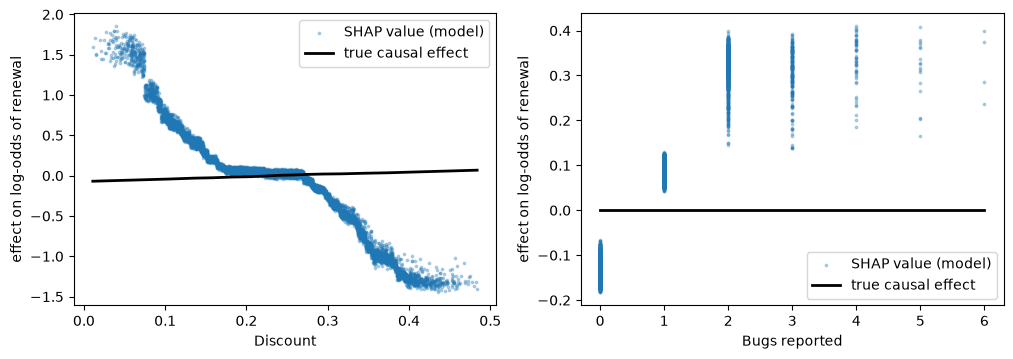

In [43]:
def true_effect(column, values, n=10_000):
    rates = np.array([generator(n, fixed={column: v}, seed=0)["Did renew"].mean() for v in values])
    effect = scipy.special.logit(rates)
    return effect - effect.mean()


fig, axes = plt.subplots(1, 2, figsize=(12, 3.8))
for ax, col in zip(axes, ["Discount", "Bugs reported"]):
    j = list(ret_X.columns).index(col)
    ax.scatter(ret_X[col], sv_ret.values[:, j], s=3, alpha=0.3, label="SHAP value (model)")
    grid = np.unique(np.percentile(ret_X[col], np.linspace(0, 100, 15), method="nearest"))
    ax.plot(grid, true_effect(col, grid), color="k", lw=2, label="true causal effect")
    ax.set_xlabel(col)
    ax.set_ylabel("effect on log-odds of renewal")
    ax.legend()
plt.show()

The model says larger discounts go with *lower* renewal and more reported bugs with *higher* renewal. Both are real correlations in the data, and useful for predicting renewals. Both are wrong as advice: the true effect of a discount is small and positive, and reporting a bug has no effect at all. The hidden variable, product need, drives discounts, bug reports and renewals at the same time (**confounding**). Changing the world needs experiments or causal methods (the original notebook continues with double machine learning), not SHAP plots.

> 📖 **Read more:** [extras/15-permutation-importance.ipynb](extras/15-permutation-importance.ipynb) (scikit-learn gallery), [extras/16-feature-importance.ipynb](extras/16-feature-importance.ipynb) (INRIA MOOC), [extras/17-shap-census-xgboost.ipynb](extras/17-shap-census-xgboost.ipynb) and [extras/18-shap-causal-caution.ipynb](extras/18-shap-causal-caution.ipynb) (SHAP documentation): the originals, with the Titanic, California housing and Adult census data, SHAP force plots and supervised clustering, and causal methods for the retention example.

## 4 · Comparing the performance of models

A running system always has a **current model** (the "champion"), here the logistic regression of Session 8. A **challenger**, here a boosted model, should replace it only if it is better by a margin that is (a) larger than the noise of the evaluation and (b) worth its extra cost. A fair comparison needs:

1. **Same data, same splits.** Both models are scored on identical folds, so the comparison is **paired**: we look at the *difference* of the two scores in each fold.
2. **The uncertainty of the difference.** The mean difference with its spread across folds, or a statistical test (Section 4a). If the plausible range includes zero, the data do not show that the challenger is better.
3. **Costs beyond the metric.** Training and prediction time, dependencies (OpenMP, GPU), explainability requirements, monitoring and the risk of a new pipeline.

Think of a new recipe in a restaurant: it replaces the old one only if the same guests, tasting both, prefer it clearly, and if the kitchen can still cook it on a busy night.

**Predict before running.** Next we score the logistic regression and a LightGBM challenger on the same 15 folds (`RepeatedStratifiedKFold`: 5 folds, repeated 3 times with different shuffles). In how many folds will the challenger win?

In [44]:
from sklearn.compose import ColumnTransformer
from sklearn.model_selection import RepeatedStratifiedKFold, cross_val_score

current = make_pipeline(ColumnTransformer([("num", StandardScaler(), num),
                                           ("cat", OneHotEncoder(handle_unknown="ignore"), cat)]),
                        LogisticRegression(max_iter=1000))
challenger = LGBMClassifier(n_estimators=300, learning_rate=0.03, num_leaves=8, min_child_samples=40,
                            n_jobs=1, verbose=-1, random_state=0)
rcv = RepeatedStratifiedKFold(n_splits=5, n_repeats=3, random_state=0)
s_cur = cross_val_score(current, Xc_tr, y_tr, cv=rcv, scoring="roc_auc")
s_ch = cross_val_score(challenger, Xc_tr, y_tr, cv=rcv, scoring="roc_auc")
d = s_ch - s_cur
print(f"current {s_cur.mean():.4f} | challenger {s_ch.mean():.4f} | mean difference {d.mean():+.4f} "
      f"(sd {d.std(ddof=1):.4f}) | challenger wins {(d > 0).sum()} of {len(d)} folds")

current 0.8452 | challenger 0.8480 | mean difference +0.0028 (sd 0.0037) | challenger wins 12 of 15 folds


The challenger wins 12 of 15 folds, by 0.003 ROC AUC on average, with a standard deviation of 0.004 across folds. That is probably a real but tiny improvement. For churn, the honest conclusion is to **keep the logistic regression**: it is as accurate, faster, has fewer dependencies and its coefficients are easy to explain. The worked example shows a case where the same procedure gives the opposite answer.

> **Note.** Comparing many challengers on the same test set and picking the best overfits the test set, just as tuning on it would. Use cross-validation to choose; use the test set once, for the final comparison.

### 4a · A statistical test for paired cross-validation scores (depth: self-study or if time allows)

*Adapted from [Statistical comparison of models using grid search](extras/19-statistical-model-comparison.ipynb) (scikit-learn developers, BSD-3-Clause).*

Why not run an ordinary paired t-test on the 15 differences? Because the scores are not independent. Both models are evaluated on the same folds, and some folds are easier for every model. Next we check how strongly the two models' fold scores move together.

correlation of the two models' fold scores: 0.952


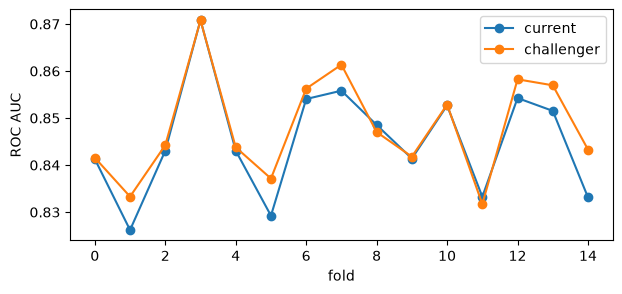

In [45]:
print("correlation of the two models' fold scores:", round(np.corrcoef(s_cur, s_ch)[0, 1], 3))
plt.figure(figsize=(7, 3))
plt.plot(s_cur, "o-", label="current")
plt.plot(s_ch, "o-", label="challenger")
plt.xlabel("fold")
plt.ylabel("ROC AUC")
plt.legend()
plt.show()

The folds also overlap: every training set shares most of its rows with the others, so even the differences are correlated, and an ordinary t-test underestimates their variance and finds "significant" differences too often. **Nadeau and Bengio's corrected t-test** inflates the variance by a term for this overlap:

t = mean difference / √( (1/(k·r) + n_test/n_train) · σ̂² ),

with k folds, r repetitions, n_test and n_train the sizes of the test and training parts of a fold, and σ̂² the variance of the differences. Next we copy the two functions of the scikit-learn example and compare the corrected with the uncorrected test.

In [46]:
from scipy.stats import t as t_dist


def corrected_std(differences, n_train, n_test):
    """Standard deviation of the differences, corrected after Nadeau and Bengio."""
    kr = len(differences)
    return np.sqrt(np.var(differences, ddof=1) * (1 / kr + n_test / n_train))


def compute_corrected_ttest(differences, df, n_train, n_test):
    """Right-tailed paired t-test with corrected variance."""
    t_stat = np.mean(differences) / corrected_std(differences, n_train, n_test)
    return t_stat, t_dist.sf(np.abs(t_stat), df)


n_train, n_test = (len(part) for part in next(rcv.split(Xc_tr, y_tr)))
df_t = len(d) - 1
t_c, p_c = compute_corrected_ttest(d, df_t, n_train, n_test)
t_u = d.mean() / np.sqrt(np.var(d, ddof=1) / len(d))
print(f"corrected:   t = {t_c:.2f}, p = {p_c:.3f}")
print(f"uncorrected: t = {t_u:.2f}, p = {t_dist.sf(abs(t_u), df_t):.3f}")

corrected:   t = 1.36, p = 0.098
uncorrected: t = 2.96, p = 0.005


The two models' fold scores are highly correlated (0.952). The uncorrected test calls the difference significant (p = 0.005); the corrected test does not (p = 0.098). The ordinary t-test would have declared a winner too easily.

A **Bayesian** view answers a more useful question: *how probable* is it that the challenger is better, and that the two are **practically equivalent**? With the same corrected variance, the posterior of the mean difference is a Student t distribution (Benavoli et al., 2017). We call the models practically equivalent if they differ by less than 0.01 ROC AUC, a **region of practical equivalence** (ROPE) that should come from the business question. Next we compute the three probabilities and the 95 % credible interval, and plot the posterior.

P(challenger better) = 0.902
P(practically equivalent, |difference| < 0.01) = 0.998
95 % credible interval of the mean difference: [-0.0016  0.0072]


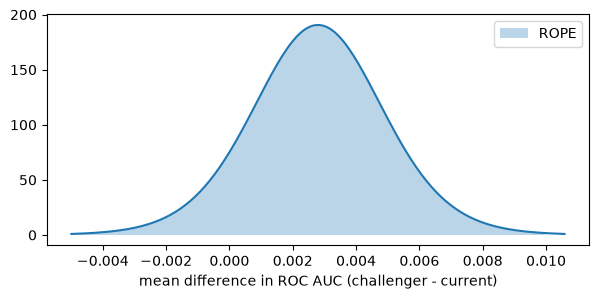

In [47]:
t_post = t_dist(df_t, loc=d.mean(), scale=corrected_std(d, n_train, n_test))
rope = (-0.01, 0.01)
print(f"P(challenger better) = {1 - t_post.cdf(0):.3f}")
print(f"P(practically equivalent, |difference| < 0.01) = {t_post.cdf(rope[1]) - t_post.cdf(rope[0]):.3f}")
print("95 % credible interval of the mean difference:", np.round(t_post.interval(0.95), 4))
xs = np.linspace(t_post.ppf(0.001), t_post.ppf(0.999), 200)
plt.figure(figsize=(7, 3))
plt.plot(xs, t_post.pdf(xs))
plt.fill_between(xs, t_post.pdf(xs), where=(xs > rope[0]) & (xs < rope[1]), alpha=0.3, label="ROPE")
plt.xlabel("mean difference in ROC AUC (challenger - current)")
plt.legend()
plt.show()

The challenger is better with probability 0.90, but with probability 0.998 the two are practically equivalent: whatever the true difference is, it is almost certainly below 0.01 ROC AUC. The 95 % credible interval runs from −0.002 to +0.007. This is the language a business decision needs.

When more than two models are compared pairwise, the frequentist p-values need a correction for multiple comparisons (for example Bonferroni: multiply each p-value by the number of comparisons); the original example shows both approaches for several models.

> 📖 **Read more:** [extras/19-statistical-model-comparison.ipynb](extras/19-statistical-model-comparison.ipynb) (scikit-learn gallery): the original, comparing four support vector machines with 10 × 10-fold cross-validation, with pairwise tests and references.

## Worked example · Is a tree ensemble worth replacing the linear price model?

**Question.** A host in Berlin wants a price suggestion for a flat. The current model is the linear regression of Session 6: log price from guests, room type, distance to Alexanderplatz and district. Is a tree ensemble worth replacing it, and what does the winner rely on?

**Data.** Inside Airbnb, Berlin, snapshot of 26 June 2026 (CC BY 4.0): the short-stay listings of Sessions 6 to 9 (minimum stay below 28 nights) with a price between €10 and €1,000. Validation keeps each host's listings in one fold (Session 7), because many hosts offer several similar flats. The leaky columns of Session 9 (`estimated_revenue_l365d`, `estimated_occupancy_l365d`) stay out until the leak check at the end.

Next we load the listings and compute the distance to Alexanderplatz in kilometres (one degree of latitude is about 111.2 km; one degree of longitude at Berlin's latitude about 68 km).

In [48]:
listings = pd.read_parquet("case-study/data/airbnb/listings.parquet")
bnb = listings[(listings["minimum_nights"] < 28) & listings["price"].between(10, 1000)].reset_index(drop=True)
bnb["dist_km"] = np.hypot((bnb["latitude"] - 52.5219) * 111.2, (bnb["longitude"] - 13.4132) * 68.0)
y_bnb, price, hosts = np.log(bnb["price"]), bnb["price"], bnb["host_id"]
print(len(bnb), "listings,", hosts.nunique(), "hosts")

6675 listings, 3737 hosts


The `amenities` column holds a JSON list per listing. Next we turn every amenity offered by at least 200 listings into a 0/1 column. `json.loads` parses a list; `explode` puts one amenity per row so that `value_counts` can count them. LightGBM needs plain column names, so `re.sub` replaces other characters with underscores.

In [49]:
import json
import re

amen_lists = bnb["amenities"].map(json.loads)
common = amen_lists.explode().value_counts().loc[lambda s: s >= 200].index
amen = pd.DataFrame({"am_" + re.sub(r"\W+", "_", a).strip("_").lower(): amen_lists.map(lambda x, a=a: a in x).astype(int)
                     for a in common})
print(len(common), "common amenities")

122 common amenities


Two feature sets: the four **Session 6 features** (one-hot encoded for the linear model), and **all features** the listing page offers: size, bedrooms, bathrooms, location, property type, minimum stay, availability, reviews and the amenities. LightGBM takes the three text columns as categories; ridge regression and the random forest get them one-hot encoded.

In [50]:
X_s6 = pd.get_dummies(bnb[["accommodates", "dist_km", "room_type", "district"]], dtype=int)
rich_num = ["accommodates", "bedrooms", "beds", "bathrooms", "dist_km", "latitude", "longitude",
            "minimum_nights", "availability_365", "number_of_reviews", "review_scores_rating"]
X_rich = pd.concat([bnb[rich_num], bnb[["room_type", "district", "property_type"]].astype("category"),
                    amen.assign(n_amenities=amen_lists.map(len))], axis=1)
X_dummies = pd.get_dummies(X_rich, dtype=int)
print(X_s6.shape, X_rich.shape, X_dummies.shape)

(6675, 18) (6675, 137) (6675, 209)


**Predict before running.** Next we score five models on the same five host-grouped folds (`GroupKFold`): the current linear model, LightGBM on the same four features, ridge regression, a random forest and LightGBM on all features. The models predict the log price; we report the mean absolute error in euros after `np.exp`. Which gains more, the extra features or the extra flexibility?

In [51]:
from lightgbm import LGBMRegressor
from sklearn.ensemble import RandomForestRegressor
from sklearn.impute import SimpleImputer
from sklearn.linear_model import LinearRegression, Ridge
from sklearn.metrics import mean_absolute_error, r2_score
from sklearn.model_selection import GroupKFold

lgbm_reg = lambda: LGBMRegressor(n_estimators=400, learning_rate=0.05, num_leaves=31, subsample=0.8, subsample_freq=1,
                                 colsample_bytree=0.5, n_jobs=1, verbose=-1, random_state=0)
price_models = {
    "current: linear, Session 6 features": (LinearRegression(), X_s6),
    "LightGBM, Session 6 features": (lgbm_reg(), X_s6),
    "ridge, all features": (make_pipeline(SimpleImputer(strategy="median", add_indicator=True), StandardScaler(),
                                          Ridge(alpha=10)), X_dummies),
    "random forest, all features": (RandomForestRegressor(200, min_samples_leaf=3, max_features=0.33,
                                                          n_jobs=4, random_state=0), X_dummies),
    "challenger: LightGBM, all features": (lgbm_reg(), X_rich),
}

The loop fits every model on the same folds, keeps the out-of-fold predictions, the MAE per fold and the time.

In [52]:
folds = list(GroupKFold(5).split(X_rich, y_bnb, groups=hosts))
fold_mae, rows = {}, []
for name, (model, X_m) in price_models.items():
    t0, pred, fold_mae[name] = time.time(), np.zeros(len(y_bnb)), []
    for tr, va in folds:
        pred[va] = model.fit(X_m.iloc[tr], y_bnb.iloc[tr]).predict(X_m.iloc[va])
        fold_mae[name].append(mean_absolute_error(price.iloc[va], np.exp(pred[va])))
    rows.append({"model": name, "R² (log)": r2_score(y_bnb, pred), "MAE €": mean_absolute_error(price, np.exp(pred)),
                 "median AE €": np.median(np.abs(price - np.exp(pred))), "seconds": time.time() - t0})
pd.DataFrame(rows).set_index("model").round(2)

,R² (log),MAE €,median AE €,seconds
model,,,,
"current: linear, Session 6 features",0.51,56.93,35.76,0.02
"LightGBM, Session 6 features",0.49,57.37,37.53,0.92
"ridge, all features",0.62,49.64,31.75,0.33
"random forest, all features",0.61,48.45,30.30,5.41
"challenger: LightGBM, all features",0.63,46.62,29.35,4.39


Next the paired comparison of Section 4: the MAE difference per fold, challenger minus current model, in euros.

In [53]:
d_price = np.array(fold_mae["challenger: LightGBM, all features"]) - np.array(fold_mae["current: linear, Session 6 features"])
print("MAE difference per fold (EUR):", d_price.round(1), "| mean", round(d_price.mean(), 1),
      "| sd", round(d_price.std(ddof=1), 1))

MAE difference per fold (EUR): [-10.2 -12.5  -9.  -10.7  -9.2] | mean -10.3 | sd 1.4


The challenger wins in every fold, by €9.0 to €12.5 a night, on average €10.3, with a standard deviation of €1.4: here the comparison of Section 4 says **replace**. The table also says *why*. With the four Session 6 features, LightGBM is no better than the linear model (MAE €57.4 against €56.9): there is little structure for a flexible model to find. Most of the gain comes from the **features**: ridge regression on all features already reaches €49.6. The tree ensembles add the rest (€48.5 for the forest, €46.6 for LightGBM) by finding interactions and thresholds that a linear model would have to be given by hand. A typical listing is still mispriced by about €29 (median absolute error), useful information for a host: the model gives a starting point, not a price.

What does the challenger rely on? Next we split off a quarter of the **hosts** as held-out data (`GroupShuffleSplit`), fit the challenger on the rest, and compute permutation importance on the held-out listings with R² as the score. We also add up the importances of all amenity columns.

In [54]:
from sklearn.model_selection import GroupShuffleSplit

tr_idx, te_idx = next(GroupShuffleSplit(1, test_size=0.25, random_state=0).split(X_rich, groups=hosts))
champion = lgbm_reg().fit(X_rich.iloc[tr_idx], y_bnb.iloc[tr_idx])
perm_p = permutation_importance(champion, X_rich.iloc[te_idx], y_bnb.iloc[te_idx], scoring="r2",
                                n_repeats=5, random_state=0, n_jobs=1)
imp_p = pd.Series(perm_p.importances_mean, index=X_rich.columns)
print("sum over all amenity columns:", round(imp_p.filter(like="am_").sum(), 3))
imp_p.nlargest(8).round(3)

sum over all amenity columns: 0.055


accommodates         0.146
property_type        0.104
bedrooms             0.091
dist_km              0.029
minimum_nights       0.027
number_of_reviews    0.023
availability_365     0.021
room_type            0.020
dtype: float64

Because the model predicts the **log** price, a SHAP value φ is a factor on the price: e^φ. Next we explain the first held-out listing: the base value and the prediction in euros, and its four largest contributions as percentage changes.

In [55]:
X_held = X_rich.iloc[te_idx]
sv_p = shap.TreeExplainer(champion)(X_held)
i = 0
print(X_held.iloc[i][["room_type", "property_type", "accommodates", "bedrooms", "dist_km"]].to_dict())
print("base price", round(float(np.exp(sv_p.base_values[i]))), "EUR -> prediction",
      round(float(np.exp(sv_p.base_values[i] + sv_p.values[i].sum()))), "EUR | actual", round(float(price.iloc[te_idx[i]])))
top = pd.Series(sv_p.values[i], index=X_rich.columns).sort_values(key=abs, ascending=False).head(4)
(100 * (np.exp(top) - 1)).round(1).rename("price change %")

{'room_type': 'Entire home/apt', 'property_type': 'Entire rental unit', 'accommodates': 2, 'bedrooms': 1.0, 'dist_km': 1.5645443855839263}
base price 158 EUR -> prediction 172 EUR | actual 161


accommodates           -10.0
property_type           10.5
dist_km                 10.1
review_scores_rating    -9.0
Name: price change %, dtype: float64

Across all held-out listings, the contribution of the distance shows the location premium the model has learned. Next we plot it as a price change in percent against the distance.

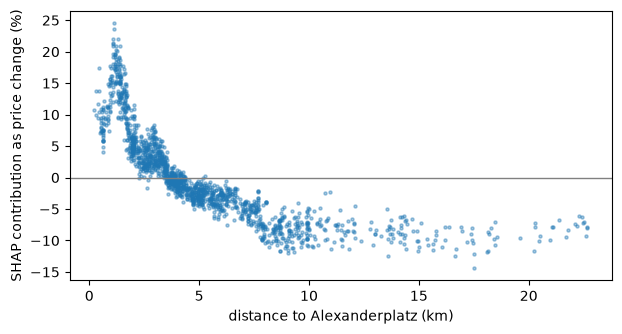

In [56]:
j = list(X_rich.columns).index("dist_km")
plt.figure(figsize=(7, 3.5))
plt.scatter(X_held["dist_km"], 100 * (np.exp(sv_p.values[:, j]) - 1), s=5, alpha=0.4)
plt.axhline(0, color="grey", lw=1)
plt.xlabel("distance to Alexanderplatz (km)")
plt.ylabel("SHAP contribution as price change (%)")
plt.show()

Permutation importance on held-out hosts puts guests (`accommodates`), property type and bedrooms first, then distance; the 122 amenities add up to 0.055 of R². Nothing dominates suspiciously, and the order matches what a host would expect. The first held-out listing, an entire flat for two guests 1.6 km from Alexanderplatz, has a base price of €158 and a prediction of €172 (actual €161): its small size lowers the price by 10 %, its property type and its central location each raise it by about 10 %. The contributions multiply, because SHAP values add on the log scale. The distance plot shows a premium of up to about 25 % close to the centre, falling to a discount of about 5 to 12 % beyond 8 km.

> **Note.** "Central location raises the price by 10 %" describes the **model**. It is not the causal effect of moving a flat (Section 3d). Location also stands for building quality and the kind of guest, which the data do not record.

**Leak check.** Finally, what would the same tools show if the leaky columns of Session 9 slipped in? Next we add Inside Airbnb's revenue and occupancy estimates (revenue is occupancy × price, so it contains the target) and compare the held-out R² and the SHAP ranking.

In [57]:
X_leak = X_rich.assign(revenue=bnb["estimated_revenue_l365d"], occupancy=bnb["estimated_occupancy_l365d"])
leaky = lgbm_reg().fit(X_leak.iloc[tr_idx], y_bnb.iloc[tr_idx])
print("held-out R² without / with the leak:",
      round(r2_score(y_bnb.iloc[te_idx], champion.predict(X_held)), 3),
      round(r2_score(y_bnb.iloc[te_idx], leaky.predict(X_leak.iloc[te_idx])), 3))
sv_leak = shap.TreeExplainer(leaky)(X_leak.iloc[te_idx])
pd.Series(np.abs(sv_leak.values).mean(axis=0), index=X_leak.columns).nlargest(5).round(3)

held-out R² without / with the leak: 0.598 0.824


revenue          0.305
occupancy        0.261
property_type    0.065
bedrooms         0.059
accommodates     0.055
dtype: float64

The held-out R² jumps from 0.598 to 0.824, and the two new columns take the first two places in the SHAP ranking, each far ahead of every honest feature. Both signals would be suspicious even if we did not know that revenue is computed from the price. The right reaction is to ask *when* each column is known, as in Session 9, not to celebrate.

## Check your understanding

1. Which parameter controls the size of a LightGBM tree, and how does LightGBM's leaf-wise growth differ from XGBoost's default?
2. With 900 stayers and 300 churners, what is `scale_pos_weight`? Why does ROC AUC barely change when you set it?
3. Why must the early-stopping validation set come from the training data and not from the test data?
4. Why can a column of random numbers get a high impurity-based importance, but not a high permutation importance on test data?
5. A challenger wins 9 of 15 folds with a mean ROC AUC difference of +0.001. Would you replace the current model? What else would you check?

## Exercises (30 min)

Work in pairs. The lecturer picks which exercises to set; there are more than fit into 30 minutes. Answer *Paper* and *Predict* tasks in the cell below the task before running any code. The code exercises use the Berlin listings `bnb` and the host-grouped `folds` of the worked example; run the setup cell first.

In [58]:
import lightgbm
from sklearn.model_selection import GroupShuffleSplit

ex_num = ["accommodates", "bedrooms", "beds", "bathrooms", "dist_km", "minimum_nights",
          "availability_365", "number_of_reviews", "review_scores_rating"]
ex_cat = ["room_type", "district", "property_type"]
print(len(bnb), "listings;", {c: bnb[c].nunique() for c in ex_cat}, "levels")

6675 listings; {'room_type': 4, 'district': 12, 'property_type': 59} levels


### 2.1 · Class weights and the call list

*Predict · 5 min*

> The retention team can call 300 customers a month and calls the 300 test customers with the highest predicted churn risk. Model A is the unweighted XGBoost churn model of Section 2; model B is the same model with `scale_pos_weight` = 2.77.
>
> Before running anything, predict: how many of the 300 customers on A's call list are also on B's list? Will B's list reach clearly more churners than A's? Then check it with `plain` and `weighted` from Section 2b (`np.argsort` of the predicted probabilities).

*Source:* original exercise for this course; background: [XGBoost parameters: `scale_pos_weight`](https://xgboost.readthedocs.io/en/stable/parameter.html)

*Your answer:*

### 2.2 · A SHAP explanation in euros

*Paper · 10 min*

> A LightGBM model predicts the **log** nightly price. For one listing, the SHAP base value is 4.50, and the contributions are +0.30 (accommodates), −0.20 (distance to Alexanderplatz) and +0.10 (room type); all other contributions are zero.
>
> 1. What is the predicted log price, and the predicted price in euros?
> 2. By what factor does the distance change the price of this listing, compared with the base value?
> 3. A host reads the explanation and says: "If my flat were closer to the centre, the price would rise by 22 %." Is this a correct reading of SHAP values? Why or why not?

*Source:* original exercise for this course; background: [Molnar, *Interpretable Machine Learning*, SHAP](https://christophm.github.io/interpretable-ml-book/shap.html)

*Your answer:*

### 2.3 · Replace the current model?

*Paper · 10 min*

> The current price model and a challenger were scored on the same five host-grouped folds (MAE in € per night):
>
> | Fold | 1 | 2 | 3 | 4 | 5 |
> |---|---|---|---|---|---|
> | Current model | 52.1 | 55.4 | 49.8 | 57.0 | 53.2 |
> | Challenger | 51.0 | 55.9 | 48.1 | 56.2 | 52.5 |
>
> Compute the paired differences, their mean and how many folds the challenger wins. The challenger needs 40 times longer to train and a new library in production. Would you replace the current model? What else would you want to know?

*Source:* original exercise for this course; background: [Bernardi, Mavridis & Estevez (2019), "150 successful machine learning models", KDD](https://doi.org/10.1145/3292500.3330744)

*Your answer:*

### 2.4 · Native categories or one-hot?

*Code · 15 min*

> Score LightGBM (`LGBMRegressor(n_estimators=300, learning_rate=0.05, n_jobs=1, verbose=-1)`) on the log price `y_bnb` with the columns `ex_num + ex_cat`, on the host-grouped `folds`, in two versions:
>
> 1. `ex_cat` as pandas `category` dtype (native categorical splits);
> 2. `ex_cat` one-hot encoded with `pd.get_dummies`.
>
> Report the cross-validated MAE in euros (`np.exp` of the predictions) and the fit time of both. Is the difference larger than the spread across the folds? The churn columns of Section 2a had at most four levels; `property_type` has many more. Does that change the conclusion?

*Source:* original exercise for this course; background: [scikit-learn example: Categorical feature support in gradient boosting](https://scikit-learn.org/stable/auto_examples/ensemble/plot_gradient_boosting_categorical.html)

### 2.5 · Early stopping and the learning rate

*Code · 15 min*

> Split the hosts once into training (80 %) and validation (20 %) with `GroupShuffleSplit(1, test_size=0.2, random_state=0)`. Train `LGBMRegressor(n_estimators=2000, n_jobs=1, verbose=-1)` on the training hosts for the learning rates 0.3, 0.1 and 0.03, with `eval_X`/`eval_y` on the validation hosts and the callback `lightgbm.early_stopping(50)`.
>
> For each learning rate, report the best number of trees (`best_iteration_`) and the validation L2 loss, and plot the validation curves (`evals_result_`). Why must the validation hosts come from the training data and not from the test data?

*Source:* original exercise for this course; background: [LightGBM: Parameters Tuning](https://lightgbm.readthedocs.io/en/stable/Parameters-Tuning.html)

### 2.6 · Amenities as a group

*Pairs · 15 min*

> *Stretch:* the worked example added up the permutation importances of the amenity columns, each shuffled on its own. Amenities come in bundles (a flat with a dishwasher often has an oven too), so shuffling one at a time may understate them.
>
> Shuffle **all** amenity columns of `X_held` together, with the same permutation of rows for the whole block, and compute the drop in held-out R² of `champion` (average over 5 shuffles). Compare it with the sum printed in the worked example. What does the difference tell you about correlated features?

*Source:* original exercise for this course; background: [scikit-learn user guide: permutation importance, misleading values on strongly correlated features](https://scikit-learn.org/stable/modules/permutation_importance.html)

## Debrief (15 min)

- **Call list (2.1).** Collect the predicted overlaps first. The usual surprise is how similar the two lists are: weights move the probabilities, not the order. Link back to ROC AUC staying the same.
- **SHAP in euros (2.2).** Look for answers that add the contributions in euros (+0.30 becoming "+€30") instead of multiplying factors e^φ, and for causal readings of the explanation.
- **Replace the model? (2.3).** Ask each pair for their decision and the one extra fact they would want. A small, consistent gain can still lose against 40 times the training time and a new production dependency.
- **Code tasks (2.4 to 2.6).** Compare the tables: were all models scored on the same `folds`, and was the early-stopping set taken from the training hosts only? In 2.6, compare the group drop with the sum of the single drops.

**Bridge to Session 11.** Both blocks predicted a known target. Session 11 asks what structure is in the data when there is no target, and adds cluster features to the gradient boosting price model of this worked example.

## Further reading

- James, G., Witten, D., Hastie, T., Tibshirani, R. & Taylor, J. (2023). *An Introduction to Statistical Learning with Applications in Python*, Section 8.2.3 (boosting). Springer. https://www.statlearning.com/
- Géron, A. (2022). *Hands-On Machine Learning with Scikit-Learn, Keras, and TensorFlow*, 3rd edition, Chapter 7 (boosting, stacking). O'Reilly.
- Chen, T. & Guestrin, C. (2016). XGBoost: a scalable tree boosting system. *Proceedings of KDD 2016*, 785–794. https://doi.org/10.1145/2939672.2939785
- Ke, G. et al. (2017). LightGBM: a highly efficient gradient boosting decision tree. *NeurIPS 30*. https://papers.nips.cc/paper_files/paper/2017/hash/6449f44a102fde848669bdd9eb6b76fa-Abstract.html
- Prokhorenkova, L., Gusev, G., Vorobev, A., Dorogush, A. V. & Gulin, A. (2018). CatBoost: unbiased boosting with categorical features. *NeurIPS 31*. https://arxiv.org/abs/1706.09516
- LightGBM developers. *Parameters Tuning*. https://lightgbm.readthedocs.io/en/stable/Parameters-Tuning.html
- Breiman, L. (2001). Random forests. *Machine Learning*, 45, 5–32 (permutation importance). https://doi.org/10.1023/A:1010933404324
- Lundberg, S. M. & Lee, S.-I. (2017). A unified approach to interpreting model predictions. *NeurIPS 30*. https://arxiv.org/abs/1705.07874
- Lundberg, S. M. et al. (2020). From local explanations to global understanding with explainable AI for trees. *Nature Machine Intelligence*, 2, 56–67. https://doi.org/10.1038/s42256-019-0138-9
- Molnar, C. *Interpretable Machine Learning*, chapters on permutation feature importance and SHAP. https://christophm.github.io/interpretable-ml-book/
- Nadeau, C. & Bengio, Y. (2003). Inference for the generalization error. *Machine Learning*, 52, 239–281. https://doi.org/10.1023/A:1024068626366
- Benavoli, A., Corani, G., Demšar, J. & Zaffalon, M. (2017). Time for a change: a tutorial for comparing multiple classifiers through Bayesian analysis. *Journal of Machine Learning Research*, 18(77), 1–36. https://jmlr.org/papers/v18/16-305.html
- Data: IBM (2019), *Telco customer churn sample data*, https://github.com/IBM/telco-customer-churn-on-icp4d (Apache-2.0); Inside Airbnb (2026), *Berlin, Germany*, snapshot of 26 June 2026, CC BY 4.0, https://insideairbnb.com/get-the-data/.
- Extras of this block (provenance in [extras/README.md](extras/README.md)): [10](extras/10-lightgbm-plotting.ipynb), [11](extras/11-catboost-tutorial.ipynb), [12](extras/12-gradient-boosting-categorical.ipynb), [13](extras/13-gradient-boosting-early-stopping.ipynb), [14](extras/14-ensemble-hyperparameters.ipynb), [15](extras/15-permutation-importance.ipynb), [16](extras/16-feature-importance.ipynb), [17](extras/17-shap-census-xgboost.ipynb), [18](extras/18-shap-causal-caution.ipynb), [19](extras/19-statistical-model-comparison.ipynb).

*Course material, licence CC BY 4.0. Sections marked "Adapted from" keep the licence of their source, named there.*